# EuroSAT Land-Use Classification with a CNN

For this project, we will use the EuroSAT dataset.

The dataset contains 10 classes:

AnnualCrop, Forest, HerbaceousVegetation, Highway, Industrial,
Pasture, PermanentCrop, Residential, River and SeaLake.

The images are RGB satellite images.

In Stage 1, we will:
- load the EuroSAT dataset
- create training, validation and test sets
- visualize some images
- define a CNN from scratch
- train the CNN
- evaluate its performance
- save the trained model


In [55]:
import torch
import torchvision
import torchvision.transforms as transforms

import matplotlib.pyplot as plt
import numpy as np

import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim


In [56]:
torch.manual_seed(42)


In [57]:
classes = (
    'AnnualCrop',
    'Forest',
    'HerbaceousVegetation',
    'Highway',
    'Industrial',
    'Pasture',
    'PermanentCrop',
    'Residential',
    'River',
    'SeaLake'
)

print(classes)


('AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake')


In [58]:
transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])

dataset = torchvision.datasets.EuroSAT(
    root='./data',
    download=True,
    transform=transform
)

print(dataset)


Dataset EuroSAT
    Number of datapoints: 27000
    Root location: ./data
    StandardTransform
Transform: Compose(
               Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
               ToTensor()
           )


In [59]:
print("Number of images:", len(dataset))
print("Classes:", dataset.classes)


Number of images: 27000
Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


In [60]:
train_size = int(0.70 * len(dataset))
val_size = int(0.15 * len(dataset))
test_size = len(dataset) - train_size - val_size

generator = torch.Generator().manual_seed(42)

train_dataset, val_dataset, test_dataset = torch.utils.data.random_split(
    dataset,
    [train_size, val_size, test_size],
    generator=generator
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))


Training images: 18900
Validation images: 4050
Test images: 4050


In [61]:
batch_size = 64

trainloader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0
)

valloader = torch.utils.data.DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

testloader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

print("DataLoaders created")


DataLoaders created


In [9]:
dataiter = iter(trainloader)
images, labels = next(dataiter)

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)


Image batch shape: torch.Size([64, 3, 64, 64])
Label batch shape: torch.Size([64])


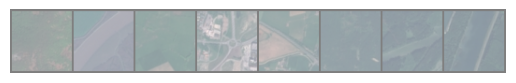

GroundTruth:           Forest           River         Pasture         Highway         Highway          Forest           River           River


In [10]:
def imshow(img):
    img = img / 2 + 0.5
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.axis('off')
    plt.show()

imshow(torchvision.utils.make_grid(images[:8]))

print(
    'GroundTruth: ',
    ' '.join('%15s' % classes[labels[j]] for j in range(8))
)


In [11]:
class Net(nn.Module):

    def __init__(self):
        super(Net, self).__init__()

        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)

        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)

        self.conv3 = nn.Conv2d(64, 128, 3, padding=1)

        self.fc1 = nn.Linear(128 * 8 * 8, 256)
        self.fc2 = nn.Linear(256, 10)

    def forward(self, x):

        x = self.pool(F.relu(self.conv1(x)))

        x = self.pool(F.relu(self.conv2(x)))

        x = self.pool(F.relu(self.conv3(x)))

        x = x.view(-1, 128 * 8 * 8)

        x = F.relu(self.fc1(x))

        x = self.fc2(x)

        return x


In [12]:
net = Net()

print(net)


Net(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=8192, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=10, bias=True)
)


In [13]:
total_params = sum(p.numel() for p in net.parameters())

print("Total parameters:", total_params)


Total parameters: 2193226


In [14]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    net.parameters(),
    lr=0.001
)


In [16]:
n_epochs = 10

train_losses = []
train_accuracies = []

val_losses = []
val_accuracies = []

for epoch in range(n_epochs):

    running_loss = 0.0
    correct = 0
    total = 0

    # Training
    net.train()

    for i, data in enumerate(trainloader, 0):

        inputs, labels = data

        # zero the parameter gradients
        optimizer.zero_grad()

        # forward + backward + optimize
        outputs = net(inputs)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        # statistics
        running_loss += loss.item()

        _, predicted = torch.max(outputs.data, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(trainloader)
    train_accuracy = correct / total

    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)

    # Validation
    net.eval()

    val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for data in valloader:

            images, labels = data

            outputs = net(images)

            loss = criterion(outputs, labels)

            val_loss += loss.item()

            _, predicted = torch.max(outputs.data, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    val_loss = val_loss / len(valloader)
    val_accuracy = correct / total

    val_losses.append(val_loss)
    val_accuracies.append(val_accuracy)

    print(
        '[%d] train loss: %.3f | train accuracy: %.2f%% | '
        'validation loss: %.3f | validation accuracy: %.2f%%'
        % (
            epoch + 1,
            train_loss,
            100 * train_accuracy,
            val_loss,
            100 * val_accuracy
        )
    )

print('Finished Training')


[1] train loss: 1.139 | train accuracy: 56.87% | validation loss: 0.734 | validation accuracy: 72.74%
[2] train loss: 0.672 | train accuracy: 75.42% | validation loss: 0.745 | validation accuracy: 72.57%
[3] train loss: 0.582 | train accuracy: 78.81% | validation loss: 0.579 | validation accuracy: 78.79%
[4] train loss: 0.488 | train accuracy: 82.10% | validation loss: 0.501 | validation accuracy: 82.44%
[5] train loss: 0.443 | train accuracy: 83.80% | validation loss: 0.464 | validation accuracy: 83.68%
[6] train loss: 0.392 | train accuracy: 86.13% | validation loss: 0.439 | validation accuracy: 83.85%
[7] train loss: 0.333 | train accuracy: 88.09% | validation loss: 0.414 | validation accuracy: 86.12%
[8] train loss: 0.278 | train accuracy: 90.10% | validation loss: 0.446 | validation accuracy: 84.59%
[9] train loss: 0.261 | train accuracy: 90.63% | validation loss: 0.418 | validation accuracy: 86.35%
[10] train loss: 0.215 | train accuracy: 92.26% | validation loss: 0.421 | validat

In [17]:
PATH = './baseline.pth'

torch.save(net.state_dict(), PATH)

print("Model saved as:", PATH)


Model saved as: ./baseline.pth


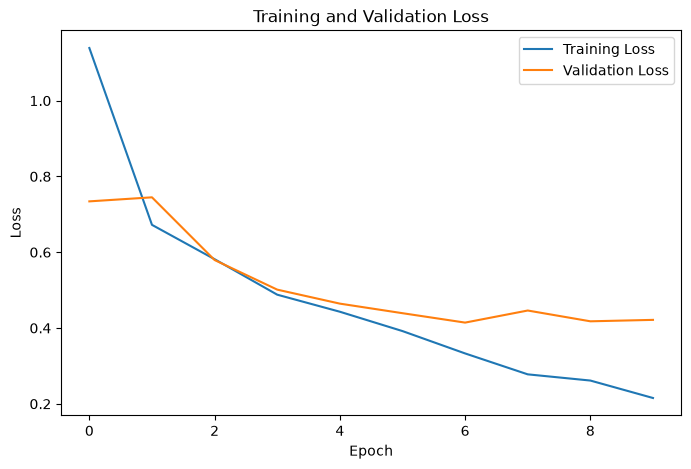

In [18]:
plt.figure(figsize=(8, 5))

plt.plot(train_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.title('Training and Validation Loss')

plt.legend()

plt.show()


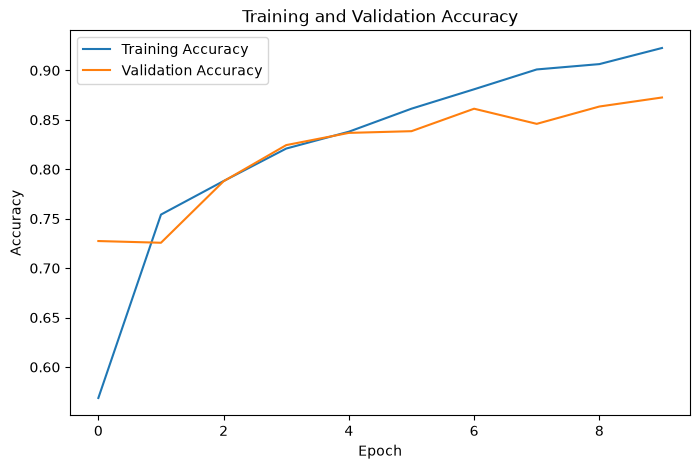

In [19]:
plt.figure(figsize=(8, 5))

plt.plot(train_accuracies, label='Training Accuracy')
plt.plot(val_accuracies, label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.title('Training and Validation Accuracy')

plt.legend()

plt.show()


In [22]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

print(device)


cpu


In [23]:
PATH = './baseline.pth'

trainednet = Net()

trainednet.load_state_dict(
    torch.load(PATH, map_location=device)
)

trainednet = trainednet.to(device)


In [24]:
correct = 0
total = 0

with torch.no_grad():

    for data in testloader:

        images, labels = data

        outputs = trainednet(images)

        _, predicted = torch.max(outputs.data, 1)

        total += labels.size(0)

        correct += (predicted == labels).sum().item()

print(
    'Accuracy of the network on the test images: %d %%'
    % (100 * correct / total)
)


Accuracy of the network on the test images: 87 %


In [26]:
class_correct = list(0. for i in range(10))
class_total = list(0. for i in range(10))

with torch.no_grad():

    for data in testloader:

        images, labels = data

        images = images.to(device)
        labels = labels.to(device)

        outputs = trainednet(images)

        _, predicted = torch.max(outputs, 1)

        c = (predicted == labels)

        for i in range(len(labels)):

            label = labels[i]

            class_correct[label] += c[i].item()
            class_total[label] += 1


In [27]:
for i in range(10):

    print(
        'Accuracy of %25s : %2d %%'
        % (
            classes[i],
            100 * class_correct[i] / class_total[i]
        )
    )


Accuracy of                AnnualCrop : 90 %
Accuracy of                    Forest : 98 %
Accuracy of      HerbaceousVegetation : 83 %
Accuracy of                   Highway : 80 %
Accuracy of                Industrial : 85 %
Accuracy of                   Pasture : 80 %
Accuracy of             PermanentCrop : 76 %
Accuracy of               Residential : 97 %
Accuracy of                     River : 80 %
Accuracy of                   SeaLake : 93 %


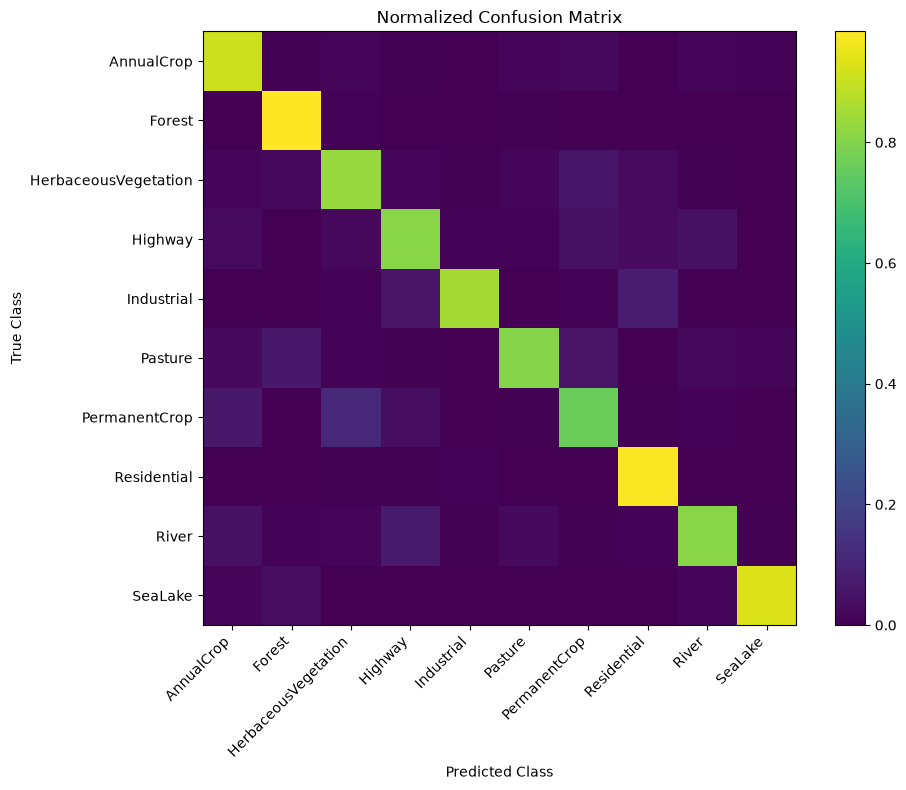

In [28]:
from sklearn.metrics import confusion_matrix

all_labels = []
all_predictions = []

trainednet.eval()

with torch.no_grad():

    for data in testloader:

        images, labels = data

        images = images.to(device)

        outputs = trainednet(images)

        _, predicted = torch.max(outputs, 1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predicted.cpu().numpy())

cm = confusion_matrix(
    all_labels,
    all_predictions,
    normalize='true'
)

plt.figure(figsize=(10, 8))

plt.imshow(cm)

plt.colorbar()

plt.xticks(
    range(10),
    classes,
    rotation=45,
    ha='right'
)

plt.yticks(
    range(10),
    classes
)

plt.xlabel('Predicted Class')
plt.ylabel('True Class')

plt.title('Normalized Confusion Matrix')

plt.tight_layout()

plt.show()


In [30]:
print("===================================")
print("STAGE 1 - BASELINE RESULTS")
print("===================================")

print("Model: Baseline CNN")
print("Classes:", len(classes))
print("Batch size:", batch_size)
print("Epochs:", n_epochs)
print("Optimizer: Adam")
print("Learning rate: 0.001")
print("Total parameters:", total_params)

print(
    "Best validation accuracy: %.2f%%"
    % (100 * max(val_accuracies))
)

print(
    "Final test accuracy: %.2f%%"
    % (100 * correct / total)
)

print("Checkpoint: baseline.pth")


STAGE 1 - BASELINE RESULTS
Model: Baseline CNN
Classes: 10
Batch size: 64
Epochs: 10
Optimizer: Adam
Learning rate: 0.001
Total parameters: 2193226
Best validation accuracy: 87.26%
Final test accuracy: 87.26%
Checkpoint: baseline.pth


# Stage 2 — Controlled CNN Architecture Experiments

The purpose of Stage 2 is to evaluate how key architectural choices affect EuroSAT classification performance while keeping the training procedure fixed.

The controlled experiments examine:

- network depth;
- convolution kernel size;
- Batch Normalization;
- convolution stride;
- convolution padding.

The Stage 1 baseline is reused as the control configuration. The test set is **not** used for model selection in Stage 2; all comparisons are based on validation performance.


### Experimental Control

To ensure a fair comparison, the following settings remain fixed across Stage 2: the EuroSAT split, preprocessing, batch size, loss function, Adam optimizer, learning rate, epoch count, and validation procedure. Only the intended architectural factor is changed in each experiment.


## 2.1 — Stage 2 Setup

Import the small additional libraries needed to measure runtime, save checkpoints, and build the final comparison table.


In [9]:
import os
import time
import pandas as pd

os.makedirs('./checkpoints', exist_ok=True)
os.makedirs('./results', exist_ok=True)

device = torch.device("cpu")
n_epochs = 10
print("Stage 2 device:", device)


Stage 2 device: cpu


**What to understand:**
- All Stage 2 experiments run on the same laptop and CPU.
- Using one machine also makes the runtime comparison more meaningful.


## 2.2 — Stage 1 Baseline Reference

The completed Stage 1 model is the control configuration: three convolutional layers, 3×3 kernels, stride 1, padding 1, and no Batch Normalization.

It is not retrained here.


In [10]:
baseline_result = {
    'Model': 'Baseline (Stage 1)',
    'Change': '3 conv / 3x3 / no BN / stride 1 / padding 1',
    'Parameters': 2193226,
    'Best Epoch': 10,
    'Peak Val Accuracy (%)': 87.26,
    'Train Accuracy at Best (%)': 92.26,
    'Generalization Gap (%)': 5.00,
    'Runtime (min)': None,
    'Latency (ms/image)': None,
    'Checkpoint': 'baseline.pth'
}

print(baseline_result)


{'Model': 'Baseline (Stage 1)', 'Change': '3 conv / 3x3 / no BN / stride 1 / padding 1', 'Parameters': 2193226, 'Best Epoch': 10, 'Peak Val Accuracy (%)': 87.26, 'Train Accuracy at Best (%)': 92.26, 'Generalization Gap (%)': 5.0, 'Runtime (min)': None, 'Latency (ms/image)': None, 'Checkpoint': 'baseline.pth'}


## 2.3 — Fair DataLoader Creation

Each independent experiment uses the same training and validation subsets.  
A fixed generator is used when the training loader is recreated so that the shuffle order is reproducible.


In [11]:
def make_stage2_loaders():

    loader_generator = torch.Generator().manual_seed(42)

    stage2_trainloader = torch.utils.data.DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=0,
        generator=loader_generator
    )

    stage2_valloader = torch.utils.data.DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0
    )

    return stage2_trainloader, stage2_valloader


**What to understand:**
- The training/validation split is exactly the same as Stage 1.
- Only the architecture is changed in Stage 2.


## 2.4 — Shared Stage 2 Training Function

The same basic PyTorch training procedure is reused for every architecture: forward pass, loss calculation, backpropagation, optimizer step, and validation.

The best checkpoint is saved according to validation accuracy.


In [12]:
def train_stage2_model(model, model_name, change, checkpoint_name):

    torch.manual_seed(42)

    model = model.to(device)

    stage2_trainloader, stage2_valloader = make_stage2_loaders()

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=0.001
    )

    train_losses = []
    train_accuracies = []
    val_losses = []
    val_accuracies = []

    best_val_accuracy = 0.0
    best_train_accuracy = 0.0
    best_epoch = 0

    checkpoint_path = os.path.join(
        './checkpoints',
        checkpoint_name
    )

    start_time = time.time()

    for epoch in range(n_epochs):

        # Training
        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for inputs, labels in stage2_trainloader:

            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(inputs)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            running_loss += loss.item()

            _, predicted = torch.max(outputs.data, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        train_loss = running_loss / len(stage2_trainloader)
        train_accuracy = correct / total

        train_losses.append(train_loss)
        train_accuracies.append(train_accuracy)

        # Validation
        model.eval()

        running_val_loss = 0.0
        correct = 0
        total = 0

        with torch.no_grad():

            for images, labels in stage2_valloader:

                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)

                loss = criterion(outputs, labels)

                running_val_loss += loss.item()

                _, predicted = torch.max(outputs.data, 1)

                total += labels.size(0)
                correct += (predicted == labels).sum().item()

        val_loss = running_val_loss / len(stage2_valloader)
        val_accuracy = correct / total

        val_losses.append(val_loss)
        val_accuracies.append(val_accuracy)

        print(
            '%s | Epoch [%d/%d] | Train Loss: %.4f | Train Acc: %.2f%% | '
            'Val Loss: %.4f | Val Acc: %.2f%%'
            % (
                model_name,
                epoch + 1,
                n_epochs,
                train_loss,
                100 * train_accuracy,
                val_loss,
                100 * val_accuracy
            )
        )

        if val_accuracy > best_val_accuracy:

            best_val_accuracy = val_accuracy
            best_train_accuracy = train_accuracy
            best_epoch = epoch + 1

            torch.save(
                model.state_dict(),
                checkpoint_path
            )

    runtime_seconds = time.time() - start_time

    # Load the best model before measuring inference latency
    model.load_state_dict(
        torch.load(
            checkpoint_path,
            map_location=device
        )
    )

    model.eval()

    images, _ = next(iter(stage2_valloader))
    images = images.to(device)

    repetitions = 10

    latency_start = time.perf_counter()

    with torch.no_grad():

        for _ in range(repetitions):
            model(images)

    latency_seconds = time.perf_counter() - latency_start

    latency_ms_per_image = (
        latency_seconds * 1000
        / repetitions
        / images.size(0)
    )

    total_params = sum(
        p.numel()
        for p in model.parameters()
    )

    generalization_gap = 100 * (
        best_train_accuracy - best_val_accuracy
    )

    result = {
        'Model': model_name,
        'Change': change,
        'Parameters': total_params,
        'Best Epoch': best_epoch,
        'Peak Val Accuracy (%)': round(100 * best_val_accuracy, 2),
        'Train Accuracy at Best (%)': round(100 * best_train_accuracy, 2),
        'Generalization Gap (%)': round(generalization_gap, 2),
        'Runtime (min)': round(runtime_seconds / 60, 2),
        'Latency (ms/image)': round(latency_ms_per_image, 4),
        'Checkpoint': checkpoint_name
    }

    history = {
        'train_loss': train_losses,
        'train_accuracy': train_accuracies,
        'val_loss': val_losses,
        'val_accuracy': val_accuracies
    }

    print()
    print("Finished:", model_name)
    print(result)
    print()

    return result, history


**What to understand:**
- `optimizer.zero_grad()` clears old gradients.
- `loss.backward()` computes new gradients.
- `optimizer.step()` updates the weights.
- Validation uses `model.eval()` and `torch.no_grad()` because no learning happens during validation.


# 2.5 — Network Depth Experiments

This experiment compares the Stage 1 three-layer baseline with a shallower two-layer CNN and a deeper four-layer CNN while keeping all training settings unchanged.


### 2.5.1 — Two-Layer CNN

This network removes one convolutional block from the baseline.


In [13]:
class Depth2Net(nn.Module):

    def __init__(self):
        super(Depth2Net, self).__init__()

        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)

        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)

        self.fc1 = nn.Linear(64 * 16 * 16, 256)
        self.fc2 = nn.Linear(256, 10)

    def forward(self, x):

        x = self.pool(F.relu(self.conv1(x)))

        x = self.pool(F.relu(self.conv2(x)))

        x = x.view(-1, 64 * 16 * 16)

        x = F.relu(self.fc1(x))

        x = self.fc2(x)

        return x


### 2.5.2 — Four-Layer CNN

This network adds one convolutional block to the baseline.


In [14]:
class Depth4Net(nn.Module):

    def __init__(self):
        super(Depth4Net, self).__init__()

        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)

        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)

        self.conv3 = nn.Conv2d(64, 128, 3, padding=1)

        self.conv4 = nn.Conv2d(128, 256, 3, padding=1)

        self.fc1 = nn.Linear(256 * 4 * 4, 256)
        self.fc2 = nn.Linear(256, 10)

    def forward(self, x):

        x = self.pool(F.relu(self.conv1(x)))

        x = self.pool(F.relu(self.conv2(x)))

        x = self.pool(F.relu(self.conv3(x)))

        x = self.pool(F.relu(self.conv4(x)))

        x = x.view(-1, 256 * 4 * 4)

        x = F.relu(self.fc1(x))

        x = self.fc2(x)

        return x


# 2.6 — Kernel Size Experiments

This experiment keeps the same three-layer baseline structure and changes only the convolution kernel size.

The Stage 1 3×3 model is used as the control, while the new experiments evaluate 5×5 and 7×7 kernels.


### 2.6.1 — Configurable Kernel CNN

Padding is adjusted to keep the feature-map size unchanged before pooling.


In [15]:
class KernelNet(nn.Module):

    def __init__(self, kernel_size):
        super(KernelNet, self).__init__()

        padding = kernel_size // 2

        self.conv1 = nn.Conv2d(
            3,
            32,
            kernel_size,
            padding=padding
        )

        self.pool = nn.MaxPool2d(2, 2)

        self.conv2 = nn.Conv2d(
            32,
            64,
            kernel_size,
            padding=padding
        )

        self.conv3 = nn.Conv2d(
            64,
            128,
            kernel_size,
            padding=padding
        )

        self.fc1 = nn.Linear(128 * 8 * 8, 256)
        self.fc2 = nn.Linear(256, 10)

    def forward(self, x):

        x = self.pool(F.relu(self.conv1(x)))

        x = self.pool(F.relu(self.conv2(x)))

        x = self.pool(F.relu(self.conv3(x)))

        x = x.view(-1, 128 * 8 * 8)

        x = F.relu(self.fc1(x))

        x = self.fc2(x)

        return x


**What to understand:** A larger kernel sees a larger local region of the image, but it also increases the number of convolution parameters.


# 2.7 — Batch Normalization, Stride, and Padding Experiments

Three controlled architectural changes are evaluated separately:

1. adding Batch Normalization after each convolution;
2. changing the first convolution stride from 1 to 2;
3. changing the first convolution padding from 1 to 0.

Each modification is tested independently against the Stage 1 baseline.


### 2.7.1 — Batch Normalization CNN

BatchNorm is added after each convolution and before ReLU.


In [16]:
class BatchNormNet(nn.Module):

    def __init__(self):
        super(BatchNormNet, self).__init__()

        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)

        self.pool = nn.MaxPool2d(2, 2)

        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)

        self.conv3 = nn.Conv2d(64, 128, 3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)

        self.fc1 = nn.Linear(128 * 8 * 8, 256)
        self.fc2 = nn.Linear(256, 10)

    def forward(self, x):

        x = self.pool(
            F.relu(self.bn1(self.conv1(x)))
        )

        x = self.pool(
            F.relu(self.bn2(self.conv2(x)))
        )

        x = self.pool(
            F.relu(self.bn3(self.conv3(x)))
        )

        x = x.view(-1, 128 * 8 * 8)

        x = F.relu(self.fc1(x))

        x = self.fc2(x)

        return x


### 2.7.2 — Stride-2 CNN

Only the first convolution stride is changed from 1 to 2.


In [17]:
class Stride2Net(nn.Module):

    def __init__(self):
        super(Stride2Net, self).__init__()

        self.conv1 = nn.Conv2d(
            3,
            32,
            3,
            stride=2,
            padding=1
        )

        self.pool = nn.MaxPool2d(2, 2)

        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)

        self.conv3 = nn.Conv2d(64, 128, 3, padding=1)

        self.fc1 = nn.Linear(128 * 4 * 4, 256)
        self.fc2 = nn.Linear(256, 10)

    def forward(self, x):

        x = self.pool(F.relu(self.conv1(x)))

        x = self.pool(F.relu(self.conv2(x)))

        x = self.pool(F.relu(self.conv3(x)))

        x = x.view(-1, 128 * 4 * 4)

        x = F.relu(self.fc1(x))

        x = self.fc2(x)

        return x


### 2.7.3 — Padding-0 CNN

Only the first convolution padding is changed from 1 to 0.


In [18]:
class Padding0Net(nn.Module):

    def __init__(self):
        super(Padding0Net, self).__init__()

        self.conv1 = nn.Conv2d(
            3,
            32,
            3,
            padding=0
        )

        self.pool = nn.MaxPool2d(2, 2)

        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)

        self.conv3 = nn.Conv2d(64, 128, 3, padding=1)

        self.fc1 = nn.Linear(128 * 7 * 7, 256)
        self.fc2 = nn.Linear(256, 10)

    def forward(self, x):

        x = self.pool(F.relu(self.conv1(x)))

        x = self.pool(F.relu(self.conv2(x)))

        x = self.pool(F.relu(self.conv3(x)))

        x = x.view(-1, 128 * 7 * 7)

        x = F.relu(self.fc1(x))

        x = self.fc2(x)

        return x


# 2.8 — Stage 2 Experiment Execution

This cell runs all seven new Stage 2 experiments sequentially using the same training configuration.

The test set is not evaluated during these experiments. Each model is selected only according to validation accuracy, and the best checkpoint for each configuration is saved automatically.


In [19]:
stage2_results = [
    baseline_result
]

stage2_histories = {}


# --------------------------------------------------
# Network depth experiments
# --------------------------------------------------

torch.manual_seed(42)

result, history = train_stage2_model(
    Depth2Net(),
    'Depth 2',
    '2 convolutional layers',
    'stage2_depth2.pth'
)

stage2_results.append(result)
stage2_histories['Depth 2'] = history


torch.manual_seed(42)

result, history = train_stage2_model(
    Depth4Net(),
    'Depth 4',
    '4 convolutional layers',
    'stage2_depth4.pth'
)

stage2_results.append(result)
stage2_histories['Depth 4'] = history


# --------------------------------------------------
# Kernel size experiments
# --------------------------------------------------

torch.manual_seed(42)

result, history = train_stage2_model(
    KernelNet(kernel_size=5),
    'Kernel 5x5',
    '5x5 kernels',
    'stage2_kernel5.pth'
)

stage2_results.append(result)
stage2_histories['Kernel 5x5'] = history


torch.manual_seed(42)

result, history = train_stage2_model(
    KernelNet(kernel_size=7),
    'Kernel 7x7',
    '7x7 kernels',
    'stage2_kernel7.pth'
)

stage2_results.append(result)
stage2_histories['Kernel 7x7'] = history


# --------------------------------------------------
# BatchNorm / stride / padding experiments
# --------------------------------------------------

torch.manual_seed(42)

result, history = train_stage2_model(
    BatchNormNet(),
    'BatchNorm',
    'BatchNorm after each convolution',
    'stage2_batchnorm.pth'
)

stage2_results.append(result)
stage2_histories['BatchNorm'] = history


torch.manual_seed(42)

result, history = train_stage2_model(
    Stride2Net(),
    'Stride 2',
    'First convolution stride = 2',
    'stage2_stride2.pth'
)

stage2_results.append(result)
stage2_histories['Stride 2'] = history


torch.manual_seed(42)

result, history = train_stage2_model(
    Padding0Net(),
    'Padding 0',
    'First convolution padding = 0',
    'stage2_padding0.pth'
)

stage2_results.append(result)
stage2_histories['Padding 0'] = history


print("===================================")
print("STAGE 2 TRAINING FINISHED")
print("===================================")


Depth 2 | Epoch [1/10] | Train Loss: 1.1505 | Train Acc: 57.12% | Val Loss: 0.7861 | Val Acc: 71.56%
Depth 2 | Epoch [2/10] | Train Loss: 0.7301 | Train Acc: 73.60% | Val Loss: 0.7002 | Val Acc: 74.79%
Depth 2 | Epoch [3/10] | Train Loss: 0.5884 | Train Acc: 78.67% | Val Loss: 0.6700 | Val Acc: 75.63%
Depth 2 | Epoch [4/10] | Train Loss: 0.5123 | Train Acc: 81.50% | Val Loss: 0.5494 | Val Acc: 80.32%
Depth 2 | Epoch [5/10] | Train Loss: 0.4563 | Train Acc: 83.68% | Val Loss: 0.5159 | Val Acc: 81.56%
Depth 2 | Epoch [6/10] | Train Loss: 0.3966 | Train Acc: 85.62% | Val Loss: 0.5464 | Val Acc: 79.43%
Depth 2 | Epoch [7/10] | Train Loss: 0.3376 | Train Acc: 87.96% | Val Loss: 0.4892 | Val Acc: 83.31%
Depth 2 | Epoch [8/10] | Train Loss: 0.2803 | Train Acc: 89.77% | Val Loss: 0.5427 | Val Acc: 82.74%
Depth 2 | Epoch [9/10] | Train Loss: 0.2505 | Train Acc: 91.18% | Val Loss: 0.5505 | Val Acc: 81.38%
Depth 2 | Epoch [10/10] | Train Loss: 0.2063 | Train Acc: 92.76% | Val Loss: 0.5183 | Val A

## 2.9 — Stage 2 Benchmark Table

Combine the Stage 1 baseline and all seven Stage 2 experiments into one benchmark table containing parameter count, peak validation accuracy, generalization gap, runtime, latency, and checkpoint information.


In [20]:
stage2_table = pd.DataFrame(stage2_results)

stage2_table = stage2_table.sort_values(
    by='Peak Val Accuracy (%)',
    ascending=False
).reset_index(drop=True)

display(stage2_table)

stage2_table.to_csv(
    './results/stage2_architecture_results.csv',
    index=False
)

print(
    "Results saved as:",
    "./results/stage2_architecture_results.csv"
)


,Model,Change,Parameters,Best Epoch,Peak Val Accuracy (%),Train Accuracy at Best (%),Generalization Gap (%),Runtime (min),Latency (ms/image),Checkpoint
0,BatchNorm,BatchNorm after each convolution,2193674,6,88.67,88.68,0.01,18.68,2.0336,stage2_batchnorm.pth
1,Depth 4,4 convolutional layers,1439818,8,87.60,86.92,-0.69,18.53,2.0001,stage2_depth4.pth
2,Baseline (Stage 1),3 conv / 3x3 / no BN / stride 1 / padding 1,2193226,10,87.26,92.26,5.00,NaN,NaN,baseline.pth
3,Padding 0,First convolution padding = 0,1701706,7,84.77,85.18,0.41,14.34,1.5328,stage2_padding0.pth
4,Depth 2,2 convolutional layers,4216522,10,83.88,92.76,8.88,17.09,1.3033,stage2_depth2.pth
5,Kernel 5x5,5x5 kernels,2358602,10,83.41,89.84,6.43,23.40,2.5951,stage2_kernel5.pth
6,Stride 2,First convolution stride = 2,620362,10,81.93,83.94,2.02,6.47,0.4426,stage2_stride2.pth
7,Kernel 7x7,7x7 kernels,2606666,9,79.41,81.81,2.40,381.41,3.8455,stage2_kernel7.pth


Results saved as: ./results/stage2_architecture_results.csv


## 2.10 — Peak Validation Accuracy Comparison

Plot the peak validation accuracy of all Stage 2 configurations.  
The best architecture will be selected from validation results and then carried forward to Stage 3.


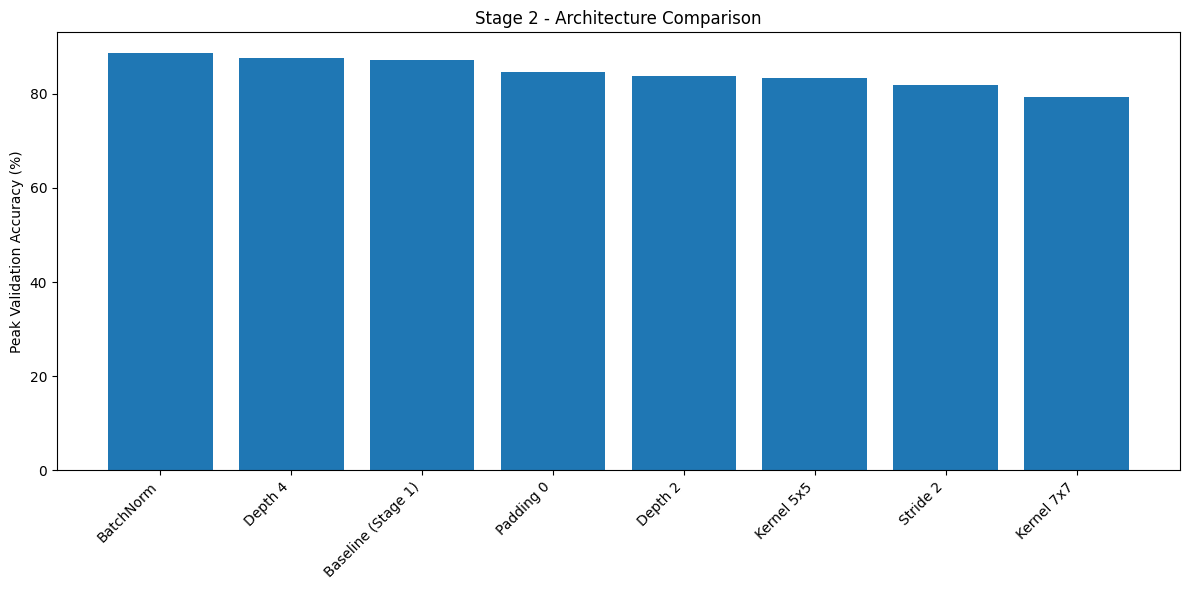

In [21]:
plt.figure(figsize=(12, 6))

plt.bar(
    stage2_table['Model'],
    stage2_table['Peak Val Accuracy (%)']
)

plt.xticks(
    rotation=45,
    ha='right'
)

plt.ylabel('Peak Validation Accuracy (%)')
plt.title('Stage 2 - Architecture Comparison')

plt.tight_layout()
plt.show()


## 2.11 — Validation Accuracy Curves

Plot the validation-accuracy curves of the seven new experiments.  
The Stage 1 baseline peak is shown as a horizontal reference line.


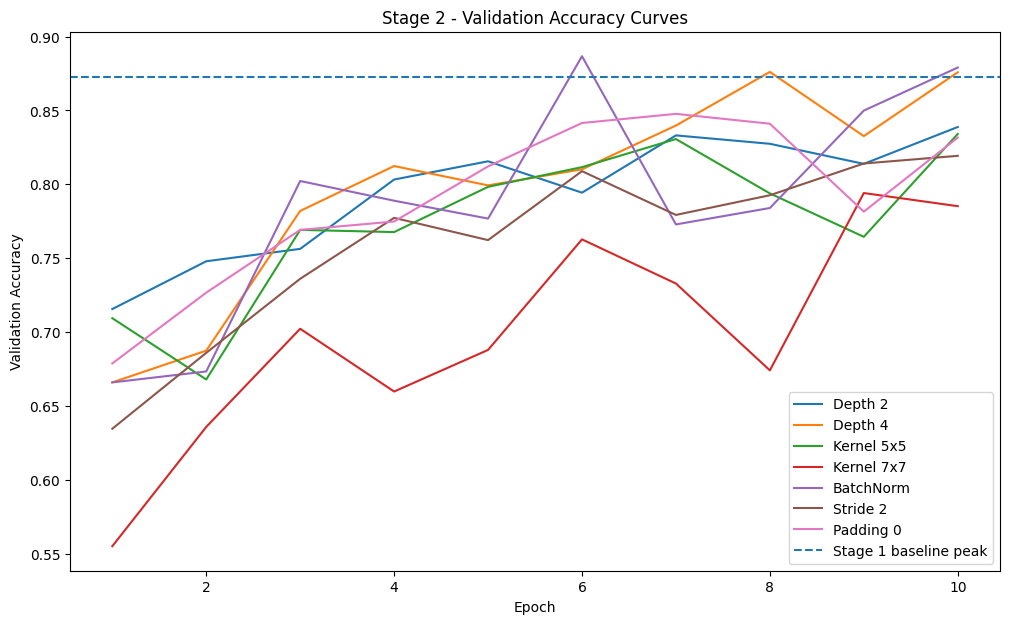

In [22]:
plt.figure(figsize=(12, 7))

for name, history in stage2_histories.items():

    plt.plot(
        range(1, n_epochs + 1),
        history['val_accuracy'],
        label=name
    )

plt.axhline(
    y=0.8726,
    linestyle='--',
    label='Stage 1 baseline peak'
)

plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')
plt.title('Stage 2 - Validation Accuracy Curves')

plt.legend()
plt.show()


## 2.12 — Stage 2 Summary and Selection Criterion

The architecture selected for Stage 3 should be chosen from the validation results only.

The decision should consider peak validation accuracy together with model complexity, generalization gap, runtime, and inference latency. The test set remains reserved for later final evaluation.


### Stage 2 Summary

Stage 2 evaluated several controlled CNN architecture variations while keeping the dataset split, preprocessing, batch size, optimizer, learning rate, loss function, and number of epochs fixed. The experiments investigated network depth, kernel size, Batch Normalization, stride, and padding.

The **BatchNorm model achieved the highest peak validation accuracy of 88.67% at epoch 6**, improving on the Stage 1 baseline accuracy of **87.26%**. It also achieved a very small generalization gap of **0.01%**, while adding only a small number of parameters compared with the baseline.

Increasing the network depth to four convolutional layers also produced a strong result of **87.60% validation accuracy**, but it did not outperform the BatchNorm model. Reducing the depth to two convolutional layers decreased validation accuracy to **83.88%**.

Increasing the convolution kernel size did not improve performance. The 5×5 model reached **83.41%**, while the 7×7 model reached only **79.41%** and required substantially more computation. The 7×7 runtime was unusually high compared with the other experiments and is therefore treated as an observed runtime anomaly rather than a normal timing result.

Changing the first convolution stride to 2 greatly reduced the number of parameters and produced the lowest inference latency, but validation accuracy decreased to **81.93%**. Removing padding from the first convolution produced **84.77%** validation accuracy, which was also below the baseline.

Based primarily on validation accuracy, while also considering generalization, parameter count, runtime, and inference latency, the **three-layer CNN with 3×3 kernels, stride 1, padding 1, and Batch Normalization was selected as the architecture for Stage 3**.

The test set was not used during Stage 2 and remains reserved for final model evaluation.

# Stage 3 — Optimizer and Learning-Rate Experiments

Stage 3 keeps the selected Stage 2 architecture fixed and changes only the optimizer and learning rate.

The selected architecture is the three-layer CNN with 3×3 kernels, stride 1, padding 1, and Batch Normalization.

The following controlled experiments are performed:

- SGD with Momentum using learning rates 1e-2, 1e-3, and 1e-4;
- Adam using learning rates 1e-2, 1e-3, and 1e-4;
- AdamW using learning rates 1e-2, 1e-3, and 1e-4.

The test set is not used during Stage 3.


## 3.1 — Stage 3 Setup

To reduce experiment time while keeping the comparison fair, every optimizer/learning-rate configuration is trained for **6 epochs**. This is a screening stage, and the selected Stage 2 BatchNorm model reached its best validation result at epoch 6.

The final optimized scratch model will be trained again for a longer run in a later stage.


In [29]:
stage3_epochs = 6

device = torch.device("cpu")

os.makedirs('./checkpoints', exist_ok=True)
os.makedirs('./results', exist_ok=True)

print("Stage 3 device:", device)
print("Stage 3 epochs per experiment:", stage3_epochs)
print("Batch size:", batch_size)


Stage 3 device: cpu
Stage 3 epochs per experiment: 6
Batch size: 64


## 3.2 — Selected Architecture

The Stage 2 winning architecture is defined again here so Stage 3 is easy to read and defend independently.


In [30]:
class SelectedCNN(nn.Module):

    def __init__(self):
        super(SelectedCNN, self).__init__()

        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)

        self.pool = nn.MaxPool2d(2, 2)

        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)

        self.conv3 = nn.Conv2d(64, 128, 3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)

        self.fc1 = nn.Linear(128 * 8 * 8, 256)
        self.fc2 = nn.Linear(256, 10)

    def forward(self, x):

        x = self.pool(
            F.relu(self.bn1(self.conv1(x)))
        )

        x = self.pool(
            F.relu(self.bn2(self.conv2(x)))
        )

        x = self.pool(
            F.relu(self.bn3(self.conv3(x)))
        )

        x = x.view(-1, 128 * 8 * 8)

        x = F.relu(self.fc1(x))

        x = self.fc2(x)

        return x


## 3.3 — Stage 3 DataLoaders

The same training and validation subsets are used for every experiment. A fixed seed is used for the training shuffle so each optimizer sees the same data order.


In [31]:
def make_stage3_loaders():

    loader_generator = torch.Generator().manual_seed(42)

    stage3_trainloader = torch.utils.data.DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=0,
        generator=loader_generator
    )

    stage3_valloader = torch.utils.data.DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0
    )

    return stage3_trainloader, stage3_valloader


## 3.4 — Shared Stage 3 Training Function

This function follows the same basic PyTorch training procedure used earlier: zero the gradients, perform the forward pass, calculate the loss, call `backward()`, update the weights, and then validate with `torch.no_grad()`.

A fresh model with the same random seed is created for every experiment so the optimizer comparisons start from the same initialization.


In [32]:
def run_stage3_experiment(
    optimizer_name,
    learning_rate,
    use_scheduler=False
):

    torch.manual_seed(42)

    model = SelectedCNN().to(device)

    stage3_trainloader, stage3_valloader = make_stage3_loaders()

    criterion = nn.CrossEntropyLoss()

    if optimizer_name == 'SGD':

        optimizer = optim.SGD(
            model.parameters(),
            lr=learning_rate,
            momentum=0.9
        )

    elif optimizer_name == 'Adam':

        optimizer = optim.Adam(
            model.parameters(),
            lr=learning_rate
        )

    elif optimizer_name == 'AdamW':

        optimizer = optim.AdamW(
            model.parameters(),
            lr=learning_rate,
            weight_decay=0.01
        )

    if use_scheduler:

        scheduler = optim.lr_scheduler.StepLR(
            optimizer,
            step_size=3,
            gamma=0.1
        )

    train_losses = []
    train_accuracies = []
    val_losses = []
    val_accuracies = []

    best_val_accuracy = 0.0
    best_train_accuracy = 0.0
    best_val_loss = 0.0
    best_epoch = 0

    lr_name = {
        0.01: '1e-2',
        0.001: '1e-3',
        0.0001: '1e-4'
    }[learning_rate]

    if use_scheduler:
        scheduler_name = 'StepLR'
        checkpoint_name = (
            'stage3_' +
            optimizer_name.lower() +
            '_' +
            lr_name +
            '_scheduler.pth'
        )
    else:
        scheduler_name = 'None'
        checkpoint_name = (
            'stage3_' +
            optimizer_name.lower() +
            '_' +
            lr_name +
            '.pth'
        )

    checkpoint_path = os.path.join(
        './checkpoints',
        checkpoint_name
    )

    start_time = time.time()

    for epoch in range(stage3_epochs):

        # Training
        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for inputs, labels in stage3_trainloader:

            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(inputs)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            running_loss += loss.item()

            _, predicted = torch.max(outputs.data, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        train_loss = running_loss / len(stage3_trainloader)
        train_accuracy = correct / total

        train_losses.append(train_loss)
        train_accuracies.append(train_accuracy)

        # Validation
        model.eval()

        running_val_loss = 0.0
        correct = 0
        total = 0

        with torch.no_grad():

            for images, labels in stage3_valloader:

                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)

                loss = criterion(outputs, labels)

                running_val_loss += loss.item()

                _, predicted = torch.max(outputs.data, 1)

                total += labels.size(0)
                correct += (predicted == labels).sum().item()

        val_loss = running_val_loss / len(stage3_valloader)
        val_accuracy = correct / total

        val_losses.append(val_loss)
        val_accuracies.append(val_accuracy)

        current_lr = optimizer.param_groups[0]['lr']

        print(
            '%s | LR %.4f | Epoch [%d/%d] | '
            'Train Loss: %.4f | Train Acc: %.2f%% | '
            'Val Loss: %.4f | Val Acc: %.2f%%'
            % (
                optimizer_name,
                current_lr,
                epoch + 1,
                stage3_epochs,
                train_loss,
                100 * train_accuracy,
                val_loss,
                100 * val_accuracy
            )
        )

        if val_accuracy > best_val_accuracy:

            best_val_accuracy = val_accuracy
            best_train_accuracy = train_accuracy
            best_val_loss = val_loss
            best_epoch = epoch + 1

            torch.save(
                model.state_dict(),
                checkpoint_path
            )

        if use_scheduler:
            scheduler.step()

    runtime_seconds = time.time() - start_time

    total_params = sum(
        p.numel()
        for p in model.parameters()
    )

    generalization_gap = 100 * (
        best_train_accuracy - best_val_accuracy
    )

    result = {
        'Optimizer': optimizer_name,
        'Learning Rate': learning_rate,
        'Scheduler': scheduler_name,
        'Parameters': total_params,
        'Best Epoch': best_epoch,
        'Peak Val Accuracy (%)': round(
            100 * best_val_accuracy,
            2
        ),
        'Val Loss at Best': round(
            best_val_loss,
            4
        ),
        'Train Accuracy at Best (%)': round(
            100 * best_train_accuracy,
            2
        ),
        'Generalization Gap (%)': round(
            generalization_gap,
            2
        ),
        'Runtime (min)': round(
            runtime_seconds / 60,
            2
        ),
        'Checkpoint': checkpoint_name
    }

    history = {
        'train_loss': train_losses,
        'train_accuracy': train_accuracies,
        'val_loss': val_losses,
        'val_accuracy': val_accuracies
    }

    print()
    print("Finished:", optimizer_name, learning_rate)
    print(result)
    print()

    return result, history


## 3.5 — SGD with Momentum

Train the selected CNN with SGD + Momentum using the three required learning rates: 1e-2, 1e-3, and 1e-4.


In [33]:
stage3_results = []
stage3_histories = {}

for lr in [0.01, 0.001, 0.0001]:

    result, history = run_stage3_experiment(
        'SGD',
        lr
    )

    stage3_results.append(result)

    stage3_histories[
        'SGD ' + str(lr)
    ] = history


SGD | LR 0.0100 | Epoch [1/6] | Train Loss: 0.9949 | Train Acc: 64.44% | Val Loss: 2.0833 | Val Acc: 45.65%
SGD | LR 0.0100 | Epoch [2/6] | Train Loss: 0.6813 | Train Acc: 75.61% | Val Loss: 0.7622 | Val Acc: 72.15%
SGD | LR 0.0100 | Epoch [3/6] | Train Loss: 0.5557 | Train Acc: 80.61% | Val Loss: 0.8104 | Val Acc: 71.26%
SGD | LR 0.0100 | Epoch [4/6] | Train Loss: 0.4462 | Train Acc: 84.44% | Val Loss: 0.5208 | Val Acc: 81.95%
SGD | LR 0.0100 | Epoch [5/6] | Train Loss: 0.3940 | Train Acc: 86.38% | Val Loss: 0.6243 | Val Acc: 79.21%
SGD | LR 0.0100 | Epoch [6/6] | Train Loss: 0.3387 | Train Acc: 87.90% | Val Loss: 0.6815 | Val Acc: 79.51%

Finished: SGD 0.01
{'Optimizer': 'SGD', 'Learning Rate': 0.01, 'Scheduler': 'None', 'Parameters': 2193674, 'Best Epoch': 4, 'Peak Val Accuracy (%)': 81.95, 'Val Loss at Best': 0.5208, 'Train Accuracy at Best (%)': 84.44, 'Generalization Gap (%)': 2.49, 'Runtime (min)': 15.43, 'Checkpoint': 'stage3_sgd_1e-2.pth'}

SGD | LR 0.0010 | Epoch [1/6] | Trai

## 3.6 — Adam

Repeat the same controlled comparison using Adam and the same three learning rates.


In [34]:
for lr in [0.01, 0.001, 0.0001]:

    result, history = run_stage3_experiment(
        'Adam',
        lr
    )

    stage3_results.append(result)

    stage3_histories[
        'Adam ' + str(lr)
    ] = history


Adam | LR 0.0100 | Epoch [1/6] | Train Loss: 2.9518 | Train Acc: 34.40% | Val Loss: 1.6528 | Val Acc: 43.33%
Adam | LR 0.0100 | Epoch [2/6] | Train Loss: 1.3013 | Train Acc: 53.53% | Val Loss: 1.1596 | Val Acc: 59.33%
Adam | LR 0.0100 | Epoch [3/6] | Train Loss: 1.0001 | Train Acc: 64.56% | Val Loss: 0.9451 | Val Acc: 65.83%
Adam | LR 0.0100 | Epoch [4/6] | Train Loss: 0.7927 | Train Acc: 71.44% | Val Loss: 0.8231 | Val Acc: 71.14%
Adam | LR 0.0100 | Epoch [5/6] | Train Loss: 0.6757 | Train Acc: 76.39% | Val Loss: 0.9876 | Val Acc: 68.59%
Adam | LR 0.0100 | Epoch [6/6] | Train Loss: 0.6027 | Train Acc: 78.41% | Val Loss: 3.6532 | Val Acc: 39.14%

Finished: Adam 0.01
{'Optimizer': 'Adam', 'Learning Rate': 0.01, 'Scheduler': 'None', 'Parameters': 2193674, 'Best Epoch': 4, 'Peak Val Accuracy (%)': 71.14, 'Val Loss at Best': 0.8231, 'Train Accuracy at Best (%)': 71.44, 'Generalization Gap (%)': 0.31, 'Runtime (min)': 10.3, 'Checkpoint': 'stage3_adam_1e-2.pth'}

Adam | LR 0.0010 | Epoch [1/

## 3.7 — AdamW

Repeat the comparison using AdamW. A weight decay of 0.01 is used with AdamW.


In [35]:
for lr in [0.01, 0.001, 0.0001]:

    result, history = run_stage3_experiment(
        'AdamW',
        lr
    )

    stage3_results.append(result)

    stage3_histories[
        'AdamW ' + str(lr)
    ] = history

print("===================================")
print("9 OPTIMIZER / LR RUNS FINISHED")
print("===================================")


AdamW | LR 0.0100 | Epoch [1/6] | Train Loss: 2.9148 | Train Acc: 37.13% | Val Loss: 1.7585 | Val Acc: 42.15%
AdamW | LR 0.0100 | Epoch [2/6] | Train Loss: 1.2337 | Train Acc: 55.62% | Val Loss: 1.1367 | Val Acc: 57.56%
AdamW | LR 0.0100 | Epoch [3/6] | Train Loss: 0.9888 | Train Acc: 64.97% | Val Loss: 1.0430 | Val Acc: 62.69%
AdamW | LR 0.0100 | Epoch [4/6] | Train Loss: 0.8233 | Train Acc: 70.49% | Val Loss: 1.0063 | Val Acc: 64.89%
AdamW | LR 0.0100 | Epoch [5/6] | Train Loss: 0.6990 | Train Acc: 75.14% | Val Loss: 0.8034 | Val Acc: 73.21%
AdamW | LR 0.0100 | Epoch [6/6] | Train Loss: 0.6330 | Train Acc: 78.31% | Val Loss: 2.7481 | Val Acc: 40.72%

Finished: AdamW 0.01
{'Optimizer': 'AdamW', 'Learning Rate': 0.01, 'Scheduler': 'None', 'Parameters': 2193674, 'Best Epoch': 5, 'Peak Val Accuracy (%)': 73.21, 'Val Loss at Best': 0.8034, 'Train Accuracy at Best (%)': 75.14, 'Generalization Gap (%)': 1.93, 'Runtime (min)': 10.13, 'Checkpoint': 'stage3_adamw_1e-2.pth'}

AdamW | LR 0.0010 

## 3.8 — Optimizer and Learning-Rate Benchmark

Combine the nine controlled experiments into one table and rank them by peak validation accuracy.


In [36]:
stage3_table = pd.DataFrame(stage3_results)

stage3_table = stage3_table.sort_values(
    by=[
        'Peak Val Accuracy (%)',
        'Val Loss at Best'
    ],
    ascending=[
        False,
        True
    ]
).reset_index(drop=True)

display(stage3_table)

stage3_table.to_csv(
    './results/stage3_optimizer_lr_results.csv',
    index=False
)

print(
    "Results saved as:",
    "./results/stage3_optimizer_lr_results.csv"
)


,Optimizer,Learning Rate,Scheduler,Parameters,Best Epoch,Peak Val Accuracy (%),Val Loss at Best,Train Accuracy at Best (%),Generalization Gap (%),Runtime (min),Checkpoint
0,AdamW,0.0010,None,2193674,6,88.84,0.3487,89.01,0.17,9.70,stage3_adamw_1e-3.pth
1,AdamW,0.0001,None,2193674,6,88.72,0.3375,90.23,1.52,9.74,stage3_adamw_1e-4.pth
2,Adam,0.0010,None,2193674,6,88.67,0.3359,88.68,0.01,11.00,stage3_adam_1e-3.pth
3,Adam,0.0001,None,2193674,6,88.32,0.3403,90.30,1.98,11.75,stage3_adam_1e-4.pth
4,SGD,0.0100,None,2193674,4,81.95,0.5208,84.44,2.49,15.43,stage3_sgd_1e-2.pth
5,SGD,0.0010,None,2193674,5,80.00,0.5673,86.15,6.15,10.79,stage3_sgd_1e-3.pth
6,SGD,0.0001,None,2193674,5,74.69,0.7303,74.77,0.08,10.76,stage3_sgd_1e-4.pth
7,AdamW,0.0100,None,2193674,5,73.21,0.8034,75.14,1.93,10.13,stage3_adamw_1e-2.pth
8,Adam,0.0100,None,2193674,4,71.14,0.8231,71.44,0.31,10.30,stage3_adam_1e-2.pth


Results saved as: ./results/stage3_optimizer_lr_results.csv


## 3.9 — Peak Validation Accuracy Comparison

Plot the peak validation accuracy of the nine optimizer and learning-rate configurations.


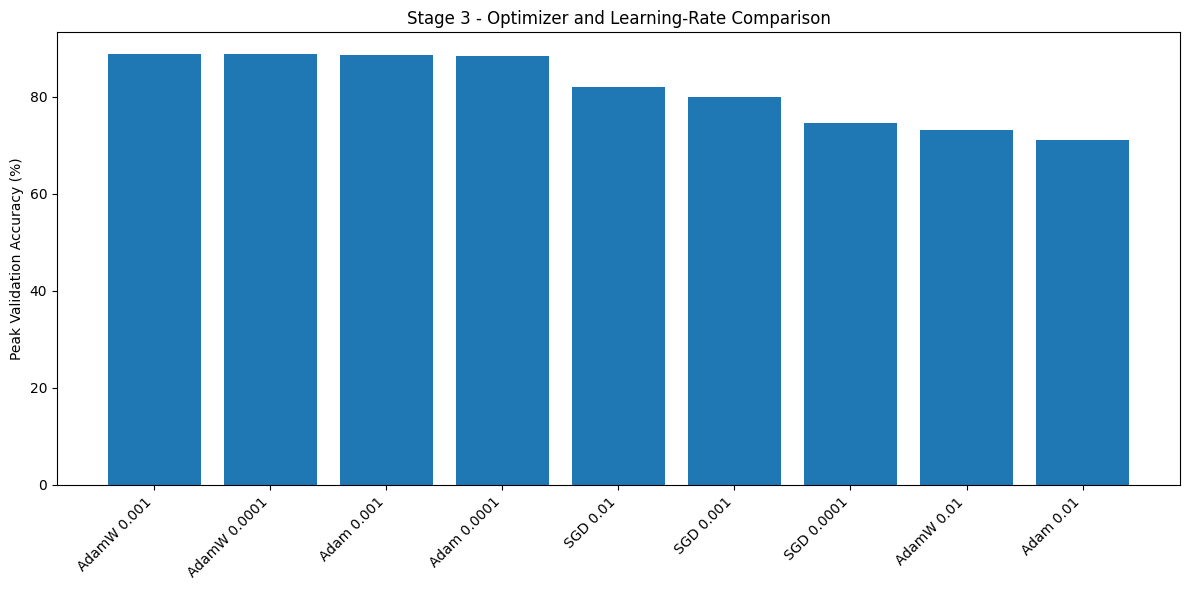

In [37]:
stage3_labels = (
    stage3_table['Optimizer']
    + ' '
    + stage3_table['Learning Rate'].astype(str)
)

plt.figure(figsize=(12, 6))

plt.bar(
    stage3_labels,
    stage3_table['Peak Val Accuracy (%)']
)

plt.xticks(
    rotation=45,
    ha='right'
)

plt.ylabel('Peak Validation Accuracy (%)')
plt.title('Stage 3 - Optimizer and Learning-Rate Comparison')

plt.tight_layout()
plt.show()


## 3.10 — Learning-Rate Scheduler Comparison

The best optimizer/learning-rate configuration from the nine runs is automatically selected.

Its existing no-scheduler result is reused as the control, so it does **not** need to be trained again. Only one additional run is performed using `StepLR`, which saves experiment time while still providing the required scheduler comparison.


In [38]:
best_stage3_row = stage3_table.iloc[0]

best_optimizer = best_stage3_row['Optimizer']
best_learning_rate = float(
    best_stage3_row['Learning Rate']
)

print(
    "Best optimizer before scheduler:",
    best_optimizer
)

print(
    "Best learning rate before scheduler:",
    best_learning_rate
)

scheduler_result, scheduler_history = run_stage3_experiment(
    best_optimizer,
    best_learning_rate,
    use_scheduler=True
)

scheduler_results = [
    best_stage3_row.to_dict(),
    scheduler_result
]


Best optimizer before scheduler: AdamW
Best learning rate before scheduler: 0.001
AdamW | LR 0.0010 | Epoch [1/6] | Train Loss: 0.9985 | Train Acc: 65.49% | Val Loss: 1.1587 | Val Acc: 61.83%
AdamW | LR 0.0010 | Epoch [2/6] | Train Loss: 0.6073 | Train Acc: 78.63% | Val Loss: 0.9566 | Val Acc: 69.01%
AdamW | LR 0.0010 | Epoch [3/6] | Train Loss: 0.4805 | Train Acc: 83.18% | Val Loss: 0.9697 | Val Acc: 69.95%
AdamW | LR 0.0001 | Epoch [4/6] | Train Loss: 0.3124 | Train Acc: 89.22% | Val Loss: 0.3855 | Val Acc: 86.37%
AdamW | LR 0.0001 | Epoch [5/6] | Train Loss: 0.2811 | Train Acc: 90.23% | Val Loss: 0.2996 | Val Acc: 90.02%
AdamW | LR 0.0001 | Epoch [6/6] | Train Loss: 0.2604 | Train Acc: 91.02% | Val Loss: 0.3122 | Val Acc: 89.43%

Finished: AdamW 0.001
{'Optimizer': 'AdamW', 'Learning Rate': 0.001, 'Scheduler': 'StepLR', 'Parameters': 2193674, 'Best Epoch': 5, 'Peak Val Accuracy (%)': 90.02, 'Val Loss at Best': 0.2996, 'Train Accuracy at Best (%)': 90.23, 'Generalization Gap (%)': 0.

## 3.11 — Scheduler Benchmark

Compare the best optimizer/learning-rate configuration with and without `StepLR`.


In [39]:
scheduler_table = pd.DataFrame(
    scheduler_results
)

scheduler_table = scheduler_table.sort_values(
    by=[
        'Peak Val Accuracy (%)',
        'Val Loss at Best'
    ],
    ascending=[
        False,
        True
    ]
).reset_index(drop=True)

display(scheduler_table)

scheduler_table.to_csv(
    './results/stage3_scheduler_results.csv',
    index=False
)

print(
    "Results saved as:",
    "./results/stage3_scheduler_results.csv"
)


,Optimizer,Learning Rate,Scheduler,Parameters,Best Epoch,Peak Val Accuracy (%),Val Loss at Best,Train Accuracy at Best (%),Generalization Gap (%),Runtime (min),Checkpoint
0,AdamW,0.001,StepLR,2193674,5,90.02,0.2996,90.23,0.21,10.11,stage3_adamw_1e-3_scheduler.pth
1,AdamW,0.001,None,2193674,6,88.84,0.3487,89.01,0.17,9.70,stage3_adamw_1e-3.pth


Results saved as: ./results/stage3_scheduler_results.csv


## 3.12 — Stage 3 Final Selection

Select the final Stage 3 training configuration using validation performance only. The test set remains reserved for the final evaluation stage.


In [40]:
final_stage3 = scheduler_table.iloc[0]

print("===================================")
print("STAGE 3 - SELECTED CONFIGURATION")
print("===================================")

print(
    "Optimizer:",
    final_stage3['Optimizer']
)

print(
    "Learning rate:",
    final_stage3['Learning Rate']
)

print(
    "Scheduler:",
    final_stage3['Scheduler']
)

print(
    "Peak validation accuracy:",
    str(final_stage3['Peak Val Accuracy (%)']) + "%"
)

print(
    "Validation loss at best epoch:",
    final_stage3['Val Loss at Best']
)

print(
    "Generalization gap:",
    str(final_stage3['Generalization Gap (%)']) + "%"
)

print(
    "Checkpoint:",
    final_stage3['Checkpoint']
)


STAGE 3 - SELECTED CONFIGURATION
Optimizer: AdamW
Learning rate: 0.001
Scheduler: StepLR
Peak validation accuracy: 90.02%
Validation loss at best epoch: 0.2996
Generalization gap: 0.21%
Checkpoint: stage3_adamw_1e-3_scheduler.pth


### Stage 3 Summary

Stage 3 compared SGD with Momentum, Adam, and AdamW using learning rates of 1e-2, 1e-3, and 1e-4 while keeping the selected CNN architecture and all other training settings fixed.

Among the nine optimizer and learning-rate experiments, AdamW with a learning rate of 0.001 achieved the highest peak validation accuracy without a scheduler, reaching 88.84%. Adam with a learning rate of 0.001 achieved a similar result of 88.67%, while SGD produced lower validation accuracy across the tested learning rates.

The learning rate of 0.01 caused unstable performance for both Adam and AdamW, indicating that it was too large for this architecture. Smaller learning rates of 0.001 and 0.0001 produced more stable training and higher validation accuracy.

A StepLR scheduler was then applied to the best configuration, AdamW with an initial learning rate of 0.001. The scheduler reduced the learning rate during training and improved the peak validation accuracy from 88.84% to 90.02%. The best result occurred at epoch 5 with a validation loss of 0.2996 and a generalization gap of 0.21%.

Therefore, the training configuration selected for the next stage is:

- Optimizer: AdamW
- Initial learning rate: 0.001
- Scheduler: StepLR
- Step size: 3 epochs
- Gamma: 0.1

The test set was not used during Stage 3 and remains reserved for final evaluation.

# Stage 4 — Data Augmentation Experiments

Stage 4 keeps the architecture and training configuration selected in Stages 2 and 3 fixed, and changes only the training-data augmentation.

The selected configuration is:

- three convolutional layers with Batch Normalization;
- 3×3 kernels, stride 1, padding 1;
- AdamW optimizer;
- initial learning rate = 0.001;
- StepLR scheduler with step size 3 and gamma 0.1;
- batch size = 64.

The Stage 3 result without augmentation is reused as the control, so it is not trained again.

Three new augmentation strategies are evaluated:

1. random horizontal/vertical flips + random crop;
2. random affine transformation + ColorJitter;
3. MixUp.

The test set is not used during Stage 4.


## 4.1 — Stage 4 Setup

To save running time while keeping the comparison fair, all three augmentation experiments use **6 epochs**, matching the Stage 3 screening budget.

The final optimized scratch CNN will be trained for a longer run after the best augmentation strategy is selected.


In [41]:
import os
import time
import random
import pandas as pd

stage4_epochs = 6

device = torch.device("cpu")

os.makedirs('./checkpoints', exist_ok=True)
os.makedirs('./results', exist_ok=True)

print("Stage 4 device:", device)
print("Epochs per augmentation experiment:", stage4_epochs)
print("Batch size:", batch_size)


Stage 4 device: cpu
Epochs per augmentation experiment: 6
Batch size: 64


## 4.2 — Selected CNN Architecture

The selected BatchNorm CNN is defined again here so the Stage 4 section remains easy to read and defend.


In [42]:
class Stage4CNN(nn.Module):

    def __init__(self):
        super(Stage4CNN, self).__init__()

        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)

        self.pool = nn.MaxPool2d(2, 2)

        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)

        self.conv3 = nn.Conv2d(64, 128, 3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)

        self.fc1 = nn.Linear(128 * 8 * 8, 256)
        self.fc2 = nn.Linear(256, 10)

    def forward(self, x):

        x = self.pool(
            F.relu(self.bn1(self.conv1(x)))
        )

        x = self.pool(
            F.relu(self.bn2(self.conv2(x)))
        )

        x = self.pool(
            F.relu(self.bn3(self.conv3(x)))
        )

        x = x.view(-1, 128 * 8 * 8)

        x = F.relu(self.fc1(x))

        x = self.fc2(x)

        return x


## 4.3 — Augmentation Transforms

The validation set keeps the original Stage 1 preprocessing. Augmentation is applied only to the training images.

The same Stage 1 split indices are reused, so the training and validation images remain exactly the same across all experiments.


In [43]:
clean_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])

flip_crop_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomCrop(64, padding=4),
    transforms.ToTensor()
])

affine_color_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomAffine(
        degrees=15,
        translate=(0.1, 0.1)
    ),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),
    transforms.ToTensor()
])

clean_dataset_stage4 = torchvision.datasets.EuroSAT(
    root='./data',
    download=False,
    transform=clean_transform
)

flip_crop_dataset = torchvision.datasets.EuroSAT(
    root='./data',
    download=False,
    transform=flip_crop_transform
)

affine_color_dataset = torchvision.datasets.EuroSAT(
    root='./data',
    download=False,
    transform=affine_color_transform
)

clean_train_dataset = torch.utils.data.Subset(
    clean_dataset_stage4,
    train_dataset.indices
)

clean_val_dataset = torch.utils.data.Subset(
    clean_dataset_stage4,
    val_dataset.indices
)

flip_crop_train_dataset = torch.utils.data.Subset(
    flip_crop_dataset,
    train_dataset.indices
)

affine_color_train_dataset = torch.utils.data.Subset(
    affine_color_dataset,
    train_dataset.indices
)

print("Training images:", len(clean_train_dataset))
print("Validation images:", len(clean_val_dataset))


Training images: 18900
Validation images: 4050


## 4.4 — Stage 4 DataLoaders

A fresh training loader is created for each experiment using the same fixed seed. The validation loader always uses clean, non-augmented images.


In [44]:
def make_stage4_loaders(training_dataset):

    loader_generator = torch.Generator().manual_seed(42)

    train_loader = torch.utils.data.DataLoader(
        training_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=0,
        generator=loader_generator
    )

    val_loader = torch.utils.data.DataLoader(
        clean_val_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0
    )

    return train_loader, val_loader


clean_train_loader = torch.utils.data.DataLoader(
    clean_train_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)


## 4.5 — MixUp Function

MixUp combines two images from the same training batch and also combines their labels in the loss calculation.

It is applied inside the training loop because MixUp operates on a complete tensor batch rather than on one PIL image at a time.


In [45]:
def mixup_batch(inputs, labels, alpha=0.2):

    lam = np.random.beta(alpha, alpha)

    index = torch.randperm(
        inputs.size(0),
        device=inputs.device
    )

    mixed_inputs = (
        lam * inputs
        + (1 - lam) * inputs[index]
    )

    labels_a = labels
    labels_b = labels[index]

    return mixed_inputs, labels_a, labels_b, lam


## 4.6 — Shared Stage 4 Training Function

The same simple PyTorch training loop is used for all three augmentation experiments.

For MixUp, the loss is calculated from the two mixed labels. After training, clean training accuracy is measured once using the best saved checkpoint so that the generalization gap remains meaningful and comparable.


In [46]:
def run_stage4_experiment(
    experiment_name,
    training_dataset,
    checkpoint_name,
    use_mixup=False
):

    random.seed(42)
    np.random.seed(42)
    torch.manual_seed(42)

    model = Stage4CNN().to(device)

    train_loader, val_loader = make_stage4_loaders(
        training_dataset
    )

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.AdamW(
        model.parameters(),
        lr=0.001,
        weight_decay=0.01
    )

    scheduler = optim.lr_scheduler.StepLR(
        optimizer,
        step_size=3,
        gamma=0.1
    )

    train_losses = []
    val_losses = []
    val_accuracies = []

    best_val_accuracy = 0.0
    best_val_loss = 0.0
    best_epoch = 0

    checkpoint_path = os.path.join(
        './checkpoints',
        checkpoint_name
    )

    start_time = time.time()

    for epoch in range(stage4_epochs):

        # Training
        model.train()

        running_loss = 0.0

        for inputs, labels in train_loader:

            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            if use_mixup:

                inputs, labels_a, labels_b, lam = mixup_batch(
                    inputs,
                    labels
                )

                outputs = model(inputs)

                loss = (
                    lam * criterion(outputs, labels_a)
                    + (1 - lam) * criterion(outputs, labels_b)
                )

            else:

                outputs = model(inputs)

                loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            running_loss += loss.item()

        train_loss = running_loss / len(train_loader)
        train_losses.append(train_loss)

        # Validation
        model.eval()

        running_val_loss = 0.0
        correct = 0
        total = 0

        with torch.no_grad():

            for images, labels in val_loader:

                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)

                loss = criterion(outputs, labels)

                running_val_loss += loss.item()

                _, predicted = torch.max(
                    outputs.data,
                    1
                )

                total += labels.size(0)

                correct += (
                    predicted == labels
                ).sum().item()

        val_loss = running_val_loss / len(val_loader)
        val_accuracy = correct / total

        val_losses.append(val_loss)
        val_accuracies.append(val_accuracy)

        current_lr = optimizer.param_groups[0]['lr']

        print(
            '%s | LR %.4f | Epoch [%d/%d] | '
            'Train Loss: %.4f | Val Loss: %.4f | '
            'Val Acc: %.2f%%'
            % (
                experiment_name,
                current_lr,
                epoch + 1,
                stage4_epochs,
                train_loss,
                val_loss,
                100 * val_accuracy
            )
        )

        if val_accuracy > best_val_accuracy:

            best_val_accuracy = val_accuracy
            best_val_loss = val_loss
            best_epoch = epoch + 1

            torch.save(
                model.state_dict(),
                checkpoint_path
            )

        scheduler.step()

    runtime_seconds = time.time() - start_time

    # Load the best checkpoint
    model.load_state_dict(
        torch.load(
            checkpoint_path,
            map_location=device
        )
    )

    # Clean training accuracy for the generalization gap
    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in clean_train_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            _, predicted = torch.max(
                outputs.data,
                1
            )

            total += labels.size(0)

            correct += (
                predicted == labels
            ).sum().item()

    clean_train_accuracy = correct / total

    generalization_gap = 100 * (
        clean_train_accuracy
        - best_val_accuracy
    )

    total_params = sum(
        p.numel()
        for p in model.parameters()
    )

    result = {
        'Augmentation': experiment_name,
        'Parameters': total_params,
        'Best Epoch': best_epoch,
        'Peak Val Accuracy (%)': round(
            100 * best_val_accuracy,
            2
        ),
        'Val Loss at Best': round(
            best_val_loss,
            4
        ),
        'Clean Train Accuracy (%)': round(
            100 * clean_train_accuracy,
            2
        ),
        'Generalization Gap (%)': round(
            generalization_gap,
            2
        ),
        'Runtime (min)': round(
            runtime_seconds / 60,
            2
        ),
        'Checkpoint': checkpoint_name
    }

    history = {
        'train_loss': train_losses,
        'val_loss': val_losses,
        'val_accuracy': val_accuracies
    }

    print()
    print("Finished:", experiment_name)
    print(result)
    print()

    return result, history


## 4.7 — No-Augmentation Control

The Stage 3 AdamW + StepLR result is reused as the no-augmentation control. This avoids repeating an identical training run.


In [47]:
stage4_control = {
    'Augmentation': 'No augmentation',
    'Parameters': 2193674,
    'Best Epoch': 5,
    'Peak Val Accuracy (%)': 90.02,
    'Val Loss at Best': 0.2996,
    'Clean Train Accuracy (%)': 90.23,
    'Generalization Gap (%)': 0.21,
    'Runtime (min)': 10.11,
    'Checkpoint': 'stage3_adamw_1e-3_scheduler.pth'
}

print(stage4_control)


{'Augmentation': 'No augmentation', 'Parameters': 2193674, 'Best Epoch': 5, 'Peak Val Accuracy (%)': 90.02, 'Val Loss at Best': 0.2996, 'Clean Train Accuracy (%)': 90.23, 'Generalization Gap (%)': 0.21, 'Runtime (min)': 10.11, 'Checkpoint': 'stage3_adamw_1e-3_scheduler.pth'}


## 4.8 — Random Flips + Random Crop

This experiment applies basic spatial augmentation using random horizontal/vertical flips and random cropping.


In [48]:
stage4_results = [
    stage4_control
]

stage4_histories = {}

result, history = run_stage4_experiment(
    'Flips + Crop',
    flip_crop_train_dataset,
    'stage4_flip_crop.pth'
)

stage4_results.append(result)
stage4_histories['Flips + Crop'] = history


Flips + Crop | LR 0.0010 | Epoch [1/6] | Train Loss: 0.9836 | Val Loss: 1.1408 | Val Acc: 61.31%
Flips + Crop | LR 0.0010 | Epoch [2/6] | Train Loss: 0.6359 | Val Loss: 1.6104 | Val Acc: 52.20%
Flips + Crop | LR 0.0010 | Epoch [3/6] | Train Loss: 0.5478 | Val Loss: 0.5601 | Val Acc: 80.20%
Flips + Crop | LR 0.0001 | Epoch [4/6] | Train Loss: 0.3941 | Val Loss: 0.4308 | Val Acc: 85.21%
Flips + Crop | LR 0.0001 | Epoch [5/6] | Train Loss: 0.3666 | Val Loss: 0.3536 | Val Acc: 87.88%
Flips + Crop | LR 0.0001 | Epoch [6/6] | Train Loss: 0.3434 | Val Loss: 0.3468 | Val Acc: 87.78%

Finished: Flips + Crop
{'Augmentation': 'Flips + Crop', 'Parameters': 2193674, 'Best Epoch': 5, 'Peak Val Accuracy (%)': 87.88, 'Val Loss at Best': 0.3536, 'Clean Train Accuracy (%)': 88.2, 'Generalization Gap (%)': 0.32, 'Runtime (min)': 11.91, 'Checkpoint': 'stage4_flip_crop.pth'}



## 4.9 — Random Affine + ColorJitter

This experiment combines a geometric transformation with changes in image brightness, contrast, and saturation.


In [49]:
result, history = run_stage4_experiment(
    'Affine + ColorJitter',
    affine_color_train_dataset,
    'stage4_affine_colorjitter.pth'
)

stage4_results.append(result)
stage4_histories['Affine + ColorJitter'] = history


Affine + ColorJitter | LR 0.0010 | Epoch [1/6] | Train Loss: 1.2550 | Val Loss: 0.9445 | Val Acc: 65.63%
Affine + ColorJitter | LR 0.0010 | Epoch [2/6] | Train Loss: 0.8071 | Val Loss: 0.7123 | Val Acc: 73.56%
Affine + ColorJitter | LR 0.0010 | Epoch [3/6] | Train Loss: 0.6917 | Val Loss: 1.2396 | Val Acc: 60.74%
Affine + ColorJitter | LR 0.0001 | Epoch [4/6] | Train Loss: 0.5141 | Val Loss: 0.4360 | Val Acc: 85.26%
Affine + ColorJitter | LR 0.0001 | Epoch [5/6] | Train Loss: 0.4913 | Val Loss: 0.4150 | Val Acc: 85.65%
Affine + ColorJitter | LR 0.0001 | Epoch [6/6] | Train Loss: 0.4610 | Val Loss: 0.3751 | Val Acc: 87.56%

Finished: Affine + ColorJitter
{'Augmentation': 'Affine + ColorJitter', 'Parameters': 2193674, 'Best Epoch': 6, 'Peak Val Accuracy (%)': 87.56, 'Val Loss at Best': 0.3751, 'Clean Train Accuracy (%)': 88.47, 'Generalization Gap (%)': 0.91, 'Runtime (min)': 12.43, 'Checkpoint': 'stage4_affine_colorjitter.pth'}



## 4.10 — MixUp

The final augmentation experiment uses the original clean training images and applies MixUp to each tensor batch inside the training loop.


In [50]:
result, history = run_stage4_experiment(
    'MixUp',
    clean_train_dataset,
    'stage4_mixup.pth',
    use_mixup=True
)

stage4_results.append(result)
stage4_histories['MixUp'] = history

print("===================================")
print("STAGE 4 TRAINING FINISHED")
print("===================================")


MixUp | LR 0.0010 | Epoch [1/6] | Train Loss: 1.3978 | Val Loss: 1.2517 | Val Acc: 57.83%
MixUp | LR 0.0010 | Epoch [2/6] | Train Loss: 1.0032 | Val Loss: 1.3429 | Val Acc: 57.63%
MixUp | LR 0.0010 | Epoch [3/6] | Train Loss: 0.9297 | Val Loss: 1.0531 | Val Acc: 65.26%
MixUp | LR 0.0001 | Epoch [4/6] | Train Loss: 0.7553 | Val Loss: 0.4166 | Val Acc: 87.58%
MixUp | LR 0.0001 | Epoch [5/6] | Train Loss: 0.7220 | Val Loss: 0.3624 | Val Acc: 89.78%
MixUp | LR 0.0001 | Epoch [6/6] | Train Loss: 0.7372 | Val Loss: 0.3986 | Val Acc: 87.16%

Finished: MixUp
{'Augmentation': 'MixUp', 'Parameters': 2193674, 'Best Epoch': 5, 'Peak Val Accuracy (%)': 89.78, 'Val Loss at Best': 0.3624, 'Clean Train Accuracy (%)': 90.99, 'Generalization Gap (%)': 1.21, 'Runtime (min)': 10.27, 'Checkpoint': 'stage4_mixup.pth'}

STAGE 4 TRAINING FINISHED


## 4.11 — Augmentation Benchmark

Combine the no-augmentation control and the three new augmentation experiments into one comparison table.

Inference latency is not re-measured here because augmentation is used only during training and does not change the CNN architecture used at inference time.


In [51]:
stage4_table = pd.DataFrame(
    stage4_results
)

stage4_table = stage4_table.sort_values(
    by=[
        'Peak Val Accuracy (%)',
        'Val Loss at Best'
    ],
    ascending=[
        False,
        True
    ]
).reset_index(drop=True)

display(stage4_table)

stage4_table.to_csv(
    './results/stage4_augmentation_results.csv',
    index=False
)

print(
    "Results saved as:",
    "./results/stage4_augmentation_results.csv"
)


,Augmentation,Parameters,Best Epoch,Peak Val Accuracy (%),Val Loss at Best,Clean Train Accuracy (%),Generalization Gap (%),Runtime (min),Checkpoint
0,No augmentation,2193674,5,90.02,0.2996,90.23,0.21,10.11,stage3_adamw_1e-3_scheduler.pth
1,MixUp,2193674,5,89.78,0.3624,90.99,1.21,10.27,stage4_mixup.pth
2,Flips + Crop,2193674,5,87.88,0.3536,88.20,0.32,11.91,stage4_flip_crop.pth
3,Affine + ColorJitter,2193674,6,87.56,0.3751,88.47,0.91,12.43,stage4_affine_colorjitter.pth


Results saved as: ./results/stage4_augmentation_results.csv


## 4.12 — Peak Validation Accuracy Comparison

Plot the peak validation accuracy of the control and all three augmentation strategies.


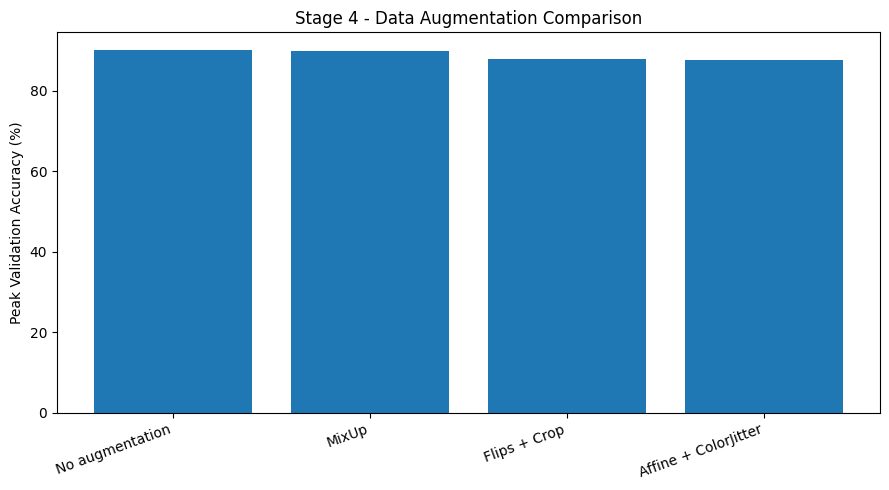

In [52]:
stage4_labels = stage4_table[
    'Augmentation'
]

plt.figure(figsize=(9, 5))

plt.bar(
    stage4_labels,
    stage4_table['Peak Val Accuracy (%)']
)

plt.xticks(
    rotation=20,
    ha='right'
)

plt.ylabel('Peak Validation Accuracy (%)')
plt.title('Stage 4 - Data Augmentation Comparison')

plt.tight_layout()
plt.show()


## 4.13 — Validation Accuracy Curves

Plot the validation curves of the three new augmentation experiments. The Stage 3 no-augmentation peak is shown as a reference line.


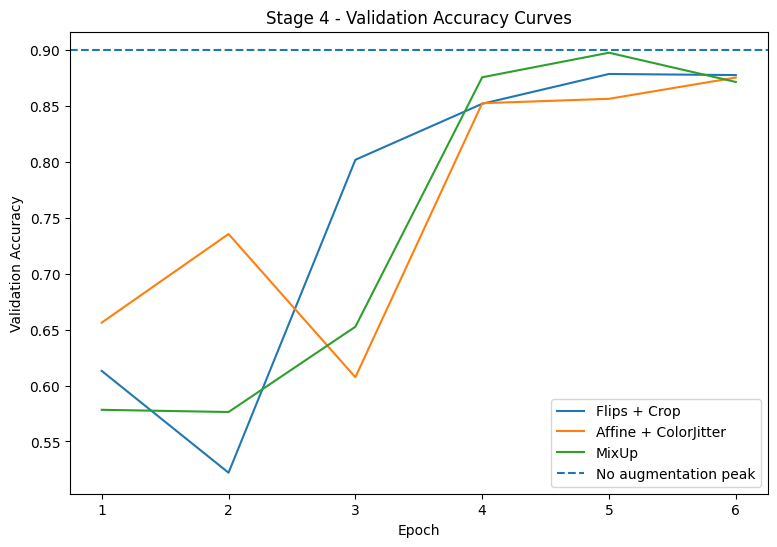

In [53]:
plt.figure(figsize=(9, 6))

for name, history in stage4_histories.items():

    plt.plot(
        range(1, stage4_epochs + 1),
        history['val_accuracy'],
        label=name
    )

plt.axhline(
    y=0.9002,
    linestyle='--',
    label='No augmentation peak'
)

plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')
plt.title('Stage 4 - Validation Accuracy Curves')

plt.legend()
plt.show()


## 4.14 — Stage 4 Final Selection

The augmentation strategy selected for the final scratch CNN should be chosen using validation performance together with the generalization gap and training behavior.

The test set remains reserved for final evaluation.


In [54]:
best_stage4 = stage4_table.iloc[0]

print("===================================")
print("STAGE 4 - SELECTED AUGMENTATION")
print("===================================")

print(
    "Augmentation:",
    best_stage4['Augmentation']
)

print(
    "Peak validation accuracy:",
    str(best_stage4['Peak Val Accuracy (%)']) + "%"
)

print(
    "Validation loss at best epoch:",
    best_stage4['Val Loss at Best']
)

print(
    "Generalization gap:",
    str(best_stage4['Generalization Gap (%)']) + "%"
)

print(
    "Checkpoint:",
    best_stage4['Checkpoint']
)


STAGE 4 - SELECTED AUGMENTATION
Augmentation: No augmentation
Peak validation accuracy: 90.02%
Validation loss at best epoch: 0.2996
Generalization gap: 0.21%
Checkpoint: stage3_adamw_1e-3_scheduler.pth


### Stage 4 Summary

Stage 4 evaluated three data-augmentation strategies while keeping the selected CNN architecture, optimizer, learning rate, scheduler, batch size, and validation procedure fixed.

The no-augmentation configuration from Stage 3 was reused as the control and achieved the highest peak validation accuracy of **90.02%**, with a validation loss of **0.2996** and a generalization gap of **0.21%**.

Among the augmentation methods, MixUp achieved the strongest result with **89.78% validation accuracy**, which was close to the control but did not exceed it. Random flips with cropping reached **87.88%**, while affine transformation with ColorJitter reached **87.56%**.

These results show that, under the current training configuration and epoch budget, the tested augmentation methods did not improve validation performance compared with training on the original images. Therefore, **no data augmentation was selected for the final optimized scratch CNN**.

The test set was not used during Stage 4 and remains reserved for final evaluation.

# Stage 5 — Final Optimized Scratch CNN

Stage 5 combines the best choices selected in the previous experiments and trains one final CNN from scratch.

Selected configuration:

- three convolutional layers;
- 3×3 kernels;
- stride 1;
- padding 1;
- Batch Normalization after each convolution;
- AdamW optimizer;
- initial learning rate = 0.001;
- StepLR scheduler with step size 3 and gamma 0.1;
- no data augmentation.

This final scratch CNN is trained for 10 epochs. The best checkpoint is selected using validation accuracy, and the test set is used only after training is complete.


## 5.1 — Final Training Setup

Set the random seed, CPU device, epoch count, and output folders for the final scratch-CNN training run.


In [62]:
import os
import time
import pandas as pd

torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cpu")

stage5_epochs = 10

os.makedirs('./checkpoints', exist_ok=True)
os.makedirs('./results', exist_ok=True)

print("Device:", device)
print("Final training epochs:", stage5_epochs)
print("Batch size:", batch_size)


Device: cpu
Final training epochs: 10
Batch size: 64


## 5.2 — Final Scratch CNN Architecture

The final network uses the architecture selected in Stage 2: three convolutional blocks with Batch Normalization.


In [63]:
class FinalScratchCNN(nn.Module):

    def __init__(self):
        super(FinalScratchCNN, self).__init__()

        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)

        self.pool = nn.MaxPool2d(2, 2)

        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)

        self.conv3 = nn.Conv2d(64, 128, 3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)

        self.fc1 = nn.Linear(128 * 8 * 8, 256)
        self.fc2 = nn.Linear(256, 10)

    def forward(self, x):

        x = self.pool(
            F.relu(self.bn1(self.conv1(x)))
        )

        x = self.pool(
            F.relu(self.bn2(self.conv2(x)))
        )

        x = self.pool(
            F.relu(self.bn3(self.conv3(x)))
        )

        x = x.view(-1, 128 * 8 * 8)

        x = F.relu(self.fc1(x))

        x = self.fc2(x)

        return x


final_model = FinalScratchCNN().to(device)

print(final_model)

final_parameters = sum(
    p.numel()
    for p in final_model.parameters()
)

print("Total parameters:", final_parameters)


FinalScratchCNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (fc1): Linear(in_features=8192, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=10, bias=True)
)
Total parameters: 2193674


## 5.3 — Final DataLoaders

Recreate the DataLoaders from the fixed Stage 1 train/validation/test split. No data augmentation is applied.

A fixed generator is used for training shuffle reproducibility.


In [64]:
stage5_generator = torch.Generator().manual_seed(42)

stage5_trainloader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0,
    generator=stage5_generator
)

stage5_valloader = torch.utils.data.DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

stage5_testloader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))


Training images: 18900
Validation images: 4050
Test images: 4050


## 5.4 — Loss Function, Optimizer, and Scheduler

Use the Stage 3 selected training configuration: CrossEntropyLoss, AdamW with learning rate 0.001, and StepLR.


In [65]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    final_model.parameters(),
    lr=0.001,
    weight_decay=0.01
)

scheduler = optim.lr_scheduler.StepLR(
    optimizer,
    step_size=3,
    gamma=0.1
)

print(optimizer)
print(scheduler)


AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    initial_lr: 0.001
    lr: 0.001
    maximize: False
    weight_decay: 0.01
)


## 5.5 — Train the Final Scratch CNN

Train for 10 epochs and record training loss, training accuracy, validation loss, and validation accuracy.

Whenever validation accuracy improves, save the model as `best_scratch_cnn.pth`.


In [66]:
train_losses = []
train_accuracies = []

val_losses = []
val_accuracies = []

best_val_accuracy = 0.0
best_val_loss = 0.0
best_train_accuracy = 0.0
best_epoch = 0

checkpoint_path = './checkpoints/best_scratch_cnn.pth'

start_time = time.time()

for epoch in range(stage5_epochs):

    # -------------------------
    # Training
    # -------------------------
    final_model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in stage5_trainloader:

        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = final_model(inputs)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(
            outputs.data,
            1
        )

        total += labels.size(0)

        correct += (
            predicted == labels
        ).sum().item()

    train_loss = running_loss / len(stage5_trainloader)
    train_accuracy = correct / total

    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)

    # -------------------------
    # Validation
    # -------------------------
    final_model.eval()

    running_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in stage5_valloader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = final_model(images)

            loss = criterion(outputs, labels)

            running_val_loss += loss.item()

            _, predicted = torch.max(
                outputs.data,
                1
            )

            total += labels.size(0)

            correct += (
                predicted == labels
            ).sum().item()

    val_loss = running_val_loss / len(stage5_valloader)
    val_accuracy = correct / total

    val_losses.append(val_loss)
    val_accuracies.append(val_accuracy)

    current_lr = optimizer.param_groups[0]['lr']

    print(
        'Epoch [%d/%d] | LR %.6f | '
        'Train Loss: %.4f | Train Acc: %.2f%% | '
        'Val Loss: %.4f | Val Acc: %.2f%%'
        % (
            epoch + 1,
            stage5_epochs,
            current_lr,
            train_loss,
            100 * train_accuracy,
            val_loss,
            100 * val_accuracy
        )
    )

    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy
        best_val_loss = val_loss
        best_train_accuracy = train_accuracy
        best_epoch = epoch + 1

        torch.save(
            final_model.state_dict(),
            checkpoint_path
        )

    scheduler.step()

training_runtime = time.time() - start_time

print()
print("Training finished.")
print("Best epoch:", best_epoch)
print(
    "Best validation accuracy: %.2f%%"
    % (100 * best_val_accuracy)
)
print(
    "Training runtime: %.2f minutes"
    % (training_runtime / 60)
)
print("Checkpoint:", checkpoint_path)


Epoch [1/10] | LR 0.001000 | Train Loss: 0.9985 | Train Acc: 65.49% | Val Loss: 1.1587 | Val Acc: 61.83%
Epoch [2/10] | LR 0.001000 | Train Loss: 0.6073 | Train Acc: 78.63% | Val Loss: 0.9566 | Val Acc: 69.01%
Epoch [3/10] | LR 0.001000 | Train Loss: 0.4805 | Train Acc: 83.18% | Val Loss: 0.9697 | Val Acc: 69.95%
Epoch [4/10] | LR 0.000100 | Train Loss: 0.3124 | Train Acc: 89.22% | Val Loss: 0.3855 | Val Acc: 86.37%
Epoch [5/10] | LR 0.000100 | Train Loss: 0.2811 | Train Acc: 90.23% | Val Loss: 0.2996 | Val Acc: 90.02%
Epoch [6/10] | LR 0.000100 | Train Loss: 0.2604 | Train Acc: 91.02% | Val Loss: 0.3122 | Val Acc: 89.43%
Epoch [7/10] | LR 0.000010 | Train Loss: 0.2402 | Train Acc: 91.77% | Val Loss: 0.2807 | Val Acc: 90.30%
Epoch [8/10] | LR 0.000010 | Train Loss: 0.2310 | Train Acc: 92.13% | Val Loss: 0.2774 | Val Acc: 90.57%
Epoch [9/10] | LR 0.000010 | Train Loss: 0.2285 | Train Acc: 92.28% | Val Loss: 0.2824 | Val Acc: 90.40%
Epoch [10/10] | LR 0.000001 | Train Loss: 0.2229 | Trai

## 5.6 — Final Learning Curves

Plot the training and validation loss curves, followed by the training and validation accuracy curves.


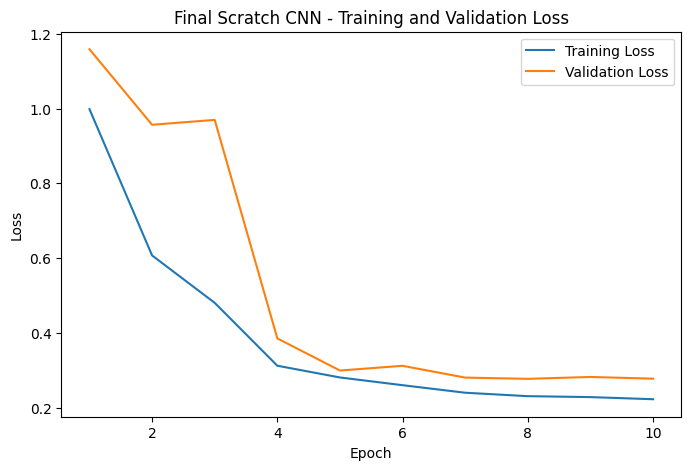

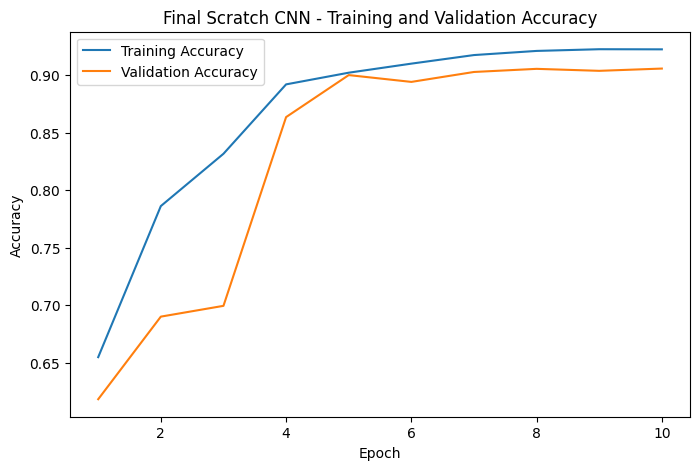

In [67]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, stage5_epochs + 1),
    train_losses,
    label='Training Loss'
)

plt.plot(
    range(1, stage5_epochs + 1),
    val_losses,
    label='Validation Loss'
)

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Final Scratch CNN - Training and Validation Loss')
plt.legend()

plt.show()


plt.figure(figsize=(8, 5))

plt.plot(
    range(1, stage5_epochs + 1),
    train_accuracies,
    label='Training Accuracy'
)

plt.plot(
    range(1, stage5_epochs + 1),
    val_accuracies,
    label='Validation Accuracy'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Final Scratch CNN - Training and Validation Accuracy')
plt.legend()

plt.show()


## 5.7 — Load the Best Final Checkpoint

Reload the checkpoint that achieved the highest validation accuracy before evaluating the unseen test set.


In [68]:
best_scratch_model = FinalScratchCNN().to(device)

best_scratch_model.load_state_dict(
    torch.load(
        './checkpoints/best_scratch_cnn.pth',
        map_location=device
    )
)

best_scratch_model.eval()

print("Best scratch CNN loaded successfully.")


Best scratch CNN loaded successfully.


## 5.8 — Final Test Accuracy and Per-Class Accuracy

Evaluate the best scratch CNN once on the reserved test set.

The same pass also records per-class correct predictions for the 10 EuroSAT classes.


In [69]:
correct = 0
total = 0

class_correct = [0.0 for i in range(10)]
class_total = [0.0 for i in range(10)]

all_labels = []
all_predictions = []

with torch.no_grad():

    for images, labels in stage5_testloader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = best_scratch_model(images)

        _, predicted = torch.max(
            outputs,
            1
        )

        total += labels.size(0)

        correct += (
            predicted == labels
        ).sum().item()

        comparison = (
            predicted == labels
        )

        for i in range(len(labels)):

            label = labels[i].item()

            class_correct[label] += comparison[i].item()
            class_total[label] += 1

        all_labels.extend(
            labels.cpu().numpy()
        )

        all_predictions.extend(
            predicted.cpu().numpy()
        )

test_accuracy = correct / total

print(
    'Final test accuracy: %.2f%%'
    % (100 * test_accuracy)
)

print()

for i in range(10):

    class_accuracy = (
        100
        * class_correct[i]
        / class_total[i]
    )

    print(
        'Accuracy of %25s : %.2f%%'
        % (
            classes[i],
            class_accuracy
        )
    )


Final test accuracy: 91.04%

Accuracy of                AnnualCrop : 89.19%
Accuracy of                    Forest : 97.06%
Accuracy of      HerbaceousVegetation : 84.93%
Accuracy of                   Highway : 85.42%
Accuracy of                Industrial : 95.77%
Accuracy of                   Pasture : 92.64%
Accuracy of             PermanentCrop : 84.70%
Accuracy of               Residential : 96.89%
Accuracy of                     River : 86.40%
Accuracy of                   SeaLake : 97.04%


## 5.9 — Normalized Test Confusion Matrix

Generate a normalized confusion matrix using the final test predictions. Each row represents the true class and is normalized to show the prediction distribution for that class.


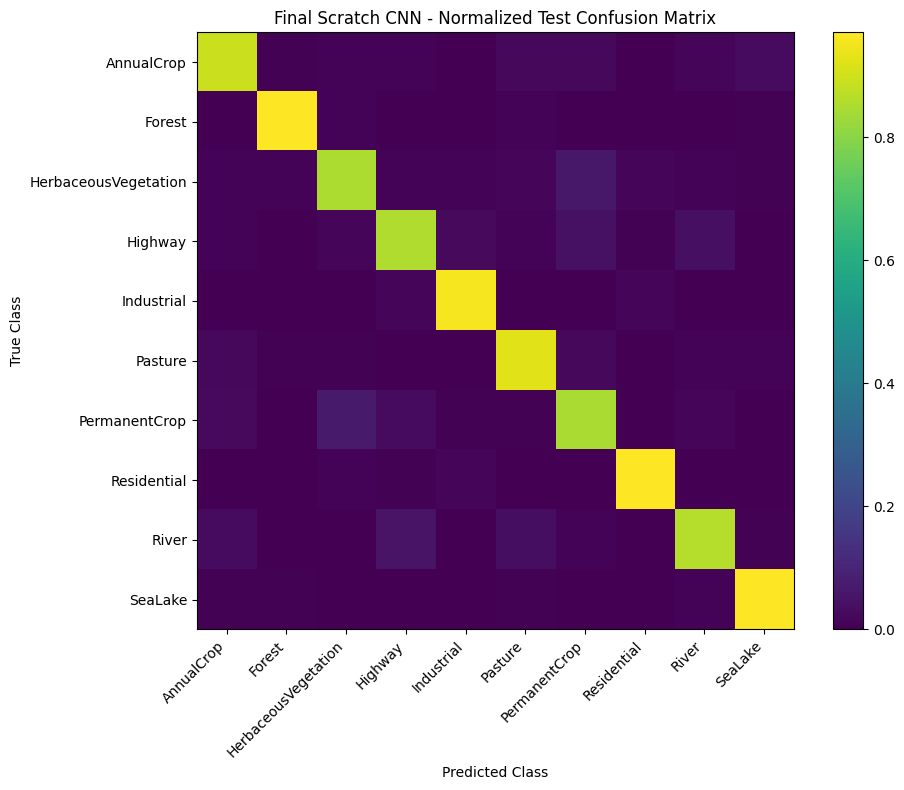

In [70]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    all_labels,
    all_predictions,
    normalize='true'
)

plt.figure(figsize=(10, 8))

plt.imshow(cm)

plt.colorbar()

plt.xticks(
    range(10),
    classes,
    rotation=45,
    ha='right'
)

plt.yticks(
    range(10),
    classes
)

plt.xlabel('Predicted Class')
plt.ylabel('True Class')

plt.title(
    'Final Scratch CNN - Normalized Test Confusion Matrix'
)

plt.tight_layout()

plt.show()


## 5.10 — Inference Latency

Measure the average CPU inference time per image using one test mini-batch and repeated forward passes.


In [71]:
images, _ = next(
    iter(stage5_testloader)
)

images = images.to(device)

repetitions = 10

latency_start = time.perf_counter()

with torch.no_grad():

    for _ in range(repetitions):

        best_scratch_model(images)

latency_seconds = (
    time.perf_counter()
    - latency_start
)

latency_ms_per_image = (
    latency_seconds
    * 1000
    / repetitions
    / images.size(0)
)

print(
    "Inference latency: %.4f ms/image"
    % latency_ms_per_image
)


Inference latency: 1.9726 ms/image


## 5.11 — Final Scratch CNN Results

Summarize the main Stage 5 results and save them to a CSV file for the final project comparison.


In [72]:
generalization_gap = 100 * (
    best_train_accuracy
    - best_val_accuracy
)

stage5_result = {
    'Model': 'Final Optimized Scratch CNN',
    'Parameters': final_parameters,
    'Best Epoch': best_epoch,
    'Peak Val Accuracy (%)': round(
        100 * best_val_accuracy,
        2
    ),
    'Val Loss at Best': round(
        best_val_loss,
        4
    ),
    'Train Accuracy at Best (%)': round(
        100 * best_train_accuracy,
        2
    ),
    'Generalization Gap (%)': round(
        generalization_gap,
        2
    ),
    'Test Accuracy (%)': round(
        100 * test_accuracy,
        2
    ),
    'Runtime (min)': round(
        training_runtime / 60,
        2
    ),
    'Latency (ms/image)': round(
        latency_ms_per_image,
        4
    ),
    'Optimizer': 'AdamW',
    'Learning Rate': 0.001,
    'Scheduler': 'StepLR',
    'Augmentation': 'None',
    'Checkpoint': 'best_scratch_cnn.pth'
}

stage5_table = pd.DataFrame(
    [stage5_result]
)

display(stage5_table)

stage5_table.to_csv(
    './results/stage5_final_scratch_results.csv',
    index=False
)

print("===================================")
print("STAGE 5 - FINAL SCRATCH CNN")
print("===================================")

print(
    "Best validation accuracy: %.2f%%"
    % (100 * best_val_accuracy)
)

print(
    "Final test accuracy: %.2f%%"
    % (100 * test_accuracy)
)

print(
    "Generalization gap: %.2f%%"
    % generalization_gap
)

print(
    "Training runtime: %.2f minutes"
    % (training_runtime / 60)
)

print(
    "Inference latency: %.4f ms/image"
    % latency_ms_per_image
)

print(
    "Checkpoint:",
    "best_scratch_cnn.pth"
)


,Model,Parameters,Best Epoch,Peak Val Accuracy (%),Val Loss at Best,Train Accuracy at Best (%),Generalization Gap (%),Test Accuracy (%),Runtime (min),Latency (ms/image),Optimizer,Learning Rate,Scheduler,Augmentation,Checkpoint
0,Final Optimized Scratch CNN,2193674,10,90.59,0.2778,92.26,1.67,91.04,21.61,1.9726,AdamW,0.001,StepLR,None,best_scratch_cnn.pth


STAGE 5 - FINAL SCRATCH CNN
Best validation accuracy: 90.59%
Final test accuracy: 91.04%
Generalization gap: 1.67%
Training runtime: 21.61 minutes
Inference latency: 1.9726 ms/image
Checkpoint: best_scratch_cnn.pth


## 5.12 — Stage 5 Completion

The final optimized CNN built from scratch has now been trained and evaluated on the reserved test set.

The saved `best_scratch_cnn.pth` checkpoint will be used later for the final comparison with transfer-learning models in Stage 6.


### Stage 5 Summary

The final optimized CNN was trained from scratch using the best configuration identified in the previous experimental stages. The selected model contains three convolutional layers with 3×3 kernels, Batch Normalization, stride 1, and padding 1. AdamW with an initial learning rate of 0.001 and a StepLR scheduler was used, with no data augmentation.

The model was trained for 10 epochs. The best validation accuracy was achieved at epoch 10, reaching **90.59%**, with a validation loss of **0.2778**. The corresponding training accuracy was **92.26%**, resulting in a generalization gap of **1.67%**.

After selecting the best checkpoint using validation performance, the model was evaluated on the previously unseen test set and achieved a final test accuracy of **91.04%**.

Per-class test accuracy showed particularly strong performance for Forest, SeaLake, Residential, and Industrial, while PermanentCrop, HerbaceousVegetation, and Highway were more difficult to classify. The normalized confusion matrix nevertheless showed a strong diagonal pattern, indicating good overall class separation.

The final model contains **2,193,674 parameters**, required approximately **21.61 minutes** to train on CPU, and achieved an average inference latency of approximately **1.97 ms per image**.

The final scratch model was saved as `best_scratch_cnn.pth` and will be used as the reference model for comparison with the transfer-learning approaches in the next stage.